# FYP — Data Preprocessing Pipeline
### Multimodal AI for Luxury Product Authentication
**Authors:** Aqsa Siddique | Aiemah Afzal 

---

This notebook prepares the dataset for **three models**:
| Model | Type | Purpose |
|---|---|---|
| CLIP ViT-B/32 | Image + Text | Primary multimodal model |
| ResNet-50 | Image only | Baseline |
| RoBERTa | Text only | Baseline |

All three share the same train/val/test split and cleaned data.  
Each gets its own transforms and tokeniser.

> **Before running:** `Runtime → Change runtime type → T4 GPU`  
> **Run cells strictly in order, top to bottom.**

---
## Cell 1 — Install Dependencies

In [ ]:
# Colab already ships with: torch, torchvision, pandas, numpy, PIL
# Only these extras are needed
!pip install -q open-clip-torch openpyxl scikit-learn tqdm transformers
print('✅ Dependencies installed')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.0 MB/s eta 0:00:00
✅ Dependencies installed


---
## Cell 2 — Imports & Seed

In [ ]:
import os, re, random, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from tqdm import tqdm

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True   # handle slightly corrupt jpegs

import torch
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

import open_clip
from transformers import RobertaTokenizer
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# Reproducibility — same seed across all three models
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'✅ Imports done')
print(f'   Device  : {DEVICE}')
print(f'   PyTorch : {torch.__version__}')

✅ Imports done
   Device  : cuda
   PyTorch : 2.10.0+cu128


---
## Cell 3 — Mount Google Drive & Set Paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# ── Update DRIVE_ROOT to match your folder location in Drive ──
# Example: if your files are at My Drive/FYP/dataset/...
# then DRIVE_ROOT = '/content/drive/MyDrive/FYP'

DRIVE_ROOT   = '/content/drive/MyDrive/dataset'              # ← changed as per user's clarification
EXCEL_PATH   = '/content/drive/MyDrive/dataset/FYP-DatasetCompilation.xlsx' # ← Corrected filename with spaces
DATASET_ROOT = DRIVE_ROOT # Dataset is directly in this root
OUTPUT_DIR   = f'{DRIVE_ROOT}/preprocessed'
IMG_SIZE     = 224   # standard for CLIP and ResNet-50

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Verify paths
print(f'Excel   : {os.path.exists(EXCEL_PATH)}  → {EXCEL_PATH}')
print(f'Dataset : {os.path.exists(DATASET_ROOT)} → {DATASET_ROOT}')
print(f'Output  : {OUTPUT_DIR}')

# Count files per folder to confirm Drive structure is correct
print('\nFolder contents:')
for cat in ['bags', 'watches', 'shoes']:
    for lbl in ['authentic', 'inauthentic']:
        folder = f'{DATASET_ROOT}/{cat}/{lbl}'
        n = len(os.listdir(folder)) if os.path.exists(folder) else 'MISSING'
        print(f'  {cat}/{lbl}: {n}')


print('\n--- Contents of your Drive_ROOT directory ---')
try:
    print(os.listdir(DRIVE_ROOT))
except FileNotFoundError:
    print(f'Error: {DRIVE_ROOT} not found. Please ensure your Drive is mounted and the path is correct.')

MessageError: Error: credential propagation was unsuccessful

---
## Cell 4 — Load Excel & Reconstruct Image Paths

In [ ]:
df = pd.read_excel(EXCEL_PATH, sheet_name='Labels')

# The ImagePath column contains an Excel formula — rebuild it in Python
# Formula: ='dataset/' & LOWER(ProductCategory) & '/' & LOWER(Label) & '/' & ImageID & '.jpeg'
df['ImagePath'] = (
    DATASET_ROOT + '/' +
    df['ProductCategory'].str.lower() + '/' +
    df['Label'].str.lower() + '/' +
    df['ImageID'].str.strip() + '.jpeg'
)

# Binary label: Authentic=1, Inauthentic=0
df['label_int'] = df['Label'].map({'Authentic': 1, 'Inauthentic': 0})

# Combined stratification key for splitting
df['strat_key'] = df['ProductCategory'] + '_' + df['Label']

print(f'✅ Excel loaded — {len(df)} rows')
print(f'   Sample path : {df["ImagePath"].iloc[0]}')

✅ Excel loaded — 2100 rows
   Sample path : /content/drive/MyDrive/dataset/bags/authentic/bag001a.jpeg


---
## Cell 5 — Data Audit

In [ ]:
print('━' * 50)
print('  DATA AUDIT')
print('━' * 50)

# Label distribution
label_counts = df['Label'].value_counts()
print('\n📊 Label distribution:')
for lbl, cnt in label_counts.items():
    print(f'   {lbl:15s}: {cnt:5d}  ({cnt/len(df)*100:.1f}%)')
ratio = label_counts['Authentic'] / label_counts['Inauthentic']
print(f'   Class imbalance ratio : {ratio:.2f}:1  (Authentic:Inauthentic)')

# Category distribution
print('\n📦 Category distribution:')
for cat, cnt in df['ProductCategory'].value_counts().items():
    print(f'   {cat:10s}: {cnt}')

# Category × Label cross-tab
print('\n📋 Category × Label cross-tab:')
print(df.groupby(['ProductCategory','Label']).size().unstack(fill_value=0).to_string())

# Text stats
df['text_len'] = df['TextDescription'].str.len()
print(f'\n📝 Text description lengths:')
print(f'   Min  : {df["text_len"].min()} chars')
print(f'   Max  : {df["text_len"].max()} chars')
print(f'   Mean : {df["text_len"].mean():.0f} chars')
over_limit = (df['text_len'] > 300).sum()
print(f'   Over 300 chars (exceeds CLIP 77-token limit approx): {over_limit}')

# Missing values
print(f'\n🔍 Missing values:')
print(df[['ImageID','Label','ProductCategory','ProductName','TextDescription']]
      .isnull().sum().to_string())

print('\n✅ Audit complete')

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  DATA AUDIT
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

📊 Label distribution:
   Authentic      :  1501  (71.5%)
   Inauthentic    :   599  (28.5%)
   Class imbalance ratio : 2.51:1  (Authentic:Inauthentic)

📦 Category distribution:
   Bags      : 700
   Watches   : 700
   Shoes     : 700

📋 Category × Label cross-tab:
Label            Authentic  Inauthentic
ProductCategory                        
Bags                   501          199
Shoes                  500          200
Watches                500          200

📝 Text description lengths:
   Min  : 45 chars
   Max  : 3269 chars
   Mean : 516 chars
   Over 300 chars (exceeds CLIP 77-token limit approx): 1309

🔍 Missing values:
ImageID            0
Label              0
ProductCategory    0
ProductName        0
TextDescription    0

✅ Audit complete


---
## Cell 6 — Text Cleaning

In [ ]:
def clean_text(text):
    if not isinstance(text, str) or text.strip() == '':
        return ''
    text = text.lower()

    # Step 1 — remove authenticity-revealing terms
    leak_words = [
        'replica', 'replicas', 'copy', 'copies', 'imitation',
        'inspired by', 'dupe', 'knockoff', 'knockoffs',
        'authentic', 'authenticity', 'genuine', 'original',
        'real', '1:1', 'aaa', 'top quality replica'
    ]
    for word in leak_words:
        text = re.sub(rf'\b{word}\b', ' ', text, flags=re.IGNORECASE)

    # Catch remaining replica variants
    text = re.sub(r'replic\w*', ' ', text, flags=re.IGNORECASE)

    # Step 2 — remove source domain style signals
    text = re.sub(r'\d+\s*x\s*\d+(\s*x\s*\d+)?', ' ', text)   # dimensions 35x25x18
    text = re.sub(r'\d+\s*cm\b', ' ', text)                     # cm measurements
    text = re.sub(r'\bsuper\b', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'high-quality', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'top quality', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'mirror quality', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'best quality', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'grade\s*[a-z0-9]+', ' ', text, flags=re.IGNORECASE)

    # Step 3 — standard cleaning
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'(usd|pkr|eur|gbp|\$|£|€)\s*[\d,]+', '', text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'[^a-z0-9\s,.\-\/]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text[:400]

df['text_clean'] = df['TextDescription'].apply(clean_text)

# Verify
print('✅ Text cleaned')
check_words = ['replica', 'copy', 'authentic', 'genuine', 'original', 'super', 'high-quality']
df_inauth = df[df['Label'] == 'Inauthentic']
for word in check_words:
    count = df_inauth['text_clean'].str.contains(word, case=False).sum()
    print(f'   {word:20s}: {count} / {len(df_inauth)}')

✅ Text cleaned
   replica             : 0 / 599
   copy                : 0 / 599
   authentic           : 0 / 599
   genuine             : 0 / 599
   original            : 0 / 599
   super               : 4 / 599
   high-quality        : 0 / 599


In [ ]:
test_path = os.path.join(DRIVE_ROOT, 'bags/authentic/bag001a.jpeg')
print("Exists:", os.path.exists(test_path))

Exists: True


---
## Cell 7 — Image Validation

In [ ]:
import os

root = "/content/drive/MyDrive/dataset"

for folder, subfolders, files in os.walk(root):
    for f in files:
        old_path = os.path.join(folder, f)

        # Strip spaces, remove '(1)' if any, and force lowercase
        name, ext = os.path.splitext(f)
        name = name.strip().replace("(1)", "").replace(" ", "")
        ext = ext.lower()

        # Standardize all to .jpeg
        if ext in ['.jpg', '.jpeg']:
            ext = '.jpeg'

        new_name = name + ext
        new_path = os.path.join(folder, new_name)

        if old_path != new_path:
            os.rename(old_path, new_path)

In [ ]:
folder = '/content/drive/MyDrive/dataset/bags/authentic'
for f in os.listdir(folder):
    if f.lower().endswith('.jpg'):
        os.rename(os.path.join(folder, f), os.path.join(folder, f.lower().replace('.jpg','.jpeg')))

In [ ]:
def validate_image(path):
    """Returns 'ok', 'missing', or 'corrupt'."""
    if not os.path.exists(path):
        return 'missing'
    try:
        img = Image.open(path)
        img.verify()
        return 'ok'
    except Exception:
        return 'corrupt'

print('🔍 Validating all images — takes 1–2 minutes...')
tqdm.pandas()
df['img_status'] = df['ImagePath'].progress_apply(validate_image)

print('\n   Image status:')
for status, cnt in df['img_status'].value_counts().items():
    print(f'   {status:10s}: {cnt}')

missing = df[df['img_status'] == 'missing']
if len(missing) > 0:
    print(f'\n⚠️  {len(missing)} missing. First 3 expected paths:')
    for p in missing['ImagePath'].head(3):
        print(f'   {p}')
    print('   → Check DRIVE_ROOT in Cell 3')

# Keep only valid images for all downstream steps
df_valid = df[df['img_status'] == 'ok'].copy().reset_index(drop=True)
print(f'\n✅ Valid rows retained: {len(df_valid)} / {len(df)}')

🔍 Validating all images — takes 1–2 minutes...


100%|██████████| 2100/2100 [13:48<00:00,  2.54it/s]


   Image status:
   ok        : 2100

✅ Valid rows retained: 2100 / 2100


---
## Cell 8 — Resolution Audit

In [ ]:
sample_paths = df_valid['ImagePath'].sample(
    n=min(300, len(df_valid)), random_state=SEED
).tolist()

widths, heights = [], []
for path in tqdm(sample_paths, desc='Auditing resolutions'):
    try:
        w, h = Image.open(path).size
        widths.append(w)
        heights.append(h)
    except Exception:
        pass

aspects = [w/h for w, h in zip(widths, heights)]

print('📐 Resolution audit (sample of 300):')
print(f'   Width  — min: {min(widths)}  max: {max(widths)}  mean: {int(np.mean(widths))}px')
print(f'   Height — min: {min(heights)}  max: {max(heights)}  mean: {int(np.mean(heights))}px')
print(f'   Aspect — min: {min(aspects):.2f}  max: {max(aspects):.2f}  mean: {np.mean(aspects):.2f}')

very_small = sum(1 for w,h in zip(widths,heights) if w < 100 or h < 100)
non_square = sum(1 for a in aspects if a < 0.75 or a > 1.33)
print(f'\n   Very small (<100px side)  : {very_small}')
print(f'   Non-square (aspect <0.75 or >1.33): {non_square} ({non_square/len(aspects)*100:.1f}%)')
print(f'\n   ✅ Standardisation method : Letterbox resize to {IMG_SIZE}×{IMG_SIZE}px')
print(f'      Aspect ratio preserved — no product features cropped')

Auditing resolutions: 100%|██████████| 300/300 [00:01<00:00, 276.98it/s]

📐 Resolution audit (sample of 300):
   Width  — min: 90  max: 8000  mean: 1344px
   Height — min: 90  max: 8000  mean: 1468px
   Aspect — min: 0.56  max: 1.62  mean: 0.93

   Very small (<100px side)  : 4
   Non-square (aspect <0.75 or >1.33): 20 (6.7%)

   ✅ Standardisation method : Letterbox resize to 224×224px
      Aspect ratio preserved — no product features cropped


---
## Cell 9 — Train / Val / Test Split

In [ ]:
# Stratify by category + label combined so proportions are
# consistent across all three splits

# Step 1 — hold out test set (20%)
df_trainval, df_test = train_test_split(
    df_valid, test_size=0.20,
    stratify=df_valid['strat_key'], random_state=SEED
)

# Step 2 — hold out val from remaining (10% of total ≈ 12.5% of trainval)
df_train, df_val = train_test_split(
    df_trainval, test_size=0.125,
    stratify=df_trainval['strat_key'], random_state=SEED
)

df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

total = len(df_valid)
print('✅ Split complete')
print(f'   Train : {len(df_train):5d}  ({len(df_train)/total*100:.1f}%)')
print(f'   Val   : {len(df_val):5d}  ({len(df_val)/total*100:.1f}%)')
print(f'   Test  : {len(df_test):5d}  ({len(df_test)/total*100:.1f}%)')

print('\n   Label balance per split:')
for name, split in [('Train', df_train), ('Val', df_val), ('Test', df_test)]:
    c = split['Label'].value_counts()
    a, i = c.get('Authentic',0), c.get('Inauthentic',0)
    print(f'   {name:5s} — Authentic: {a}  Inauthentic: {i}  Ratio: {a/max(i,1):.2f}:1')

# Save CSVs to Drive for reference
COLS = ['ImageID','ProductID','ImagePath','ProductCategory',
        'Label','label_int','ProductName','text_clean','SourceTag']
df_train[COLS].to_csv(f'{OUTPUT_DIR}/train.csv', index=False)
df_val[COLS].to_csv(f'{OUTPUT_DIR}/val.csv',     index=False)
df_test[COLS].to_csv(f'{OUTPUT_DIR}/test.csv',   index=False)
df_valid[COLS].to_csv(f'{OUTPUT_DIR}/full.csv',  index=False)
print(f'\n💾 CSVs saved to {OUTPUT_DIR}/')

✅ Split complete
   Train :  1470  (70.0%)
   Val   :   210  (10.0%)
   Test  :   420  (20.0%)

   Label balance per split:
   Train — Authentic: 1051  Inauthentic: 419  Ratio: 2.51:1
   Val   — Authentic: 150  Inauthentic: 60  Ratio: 2.50:1
   Test  — Authentic: 300  Inauthentic: 120  Ratio: 2.50:1

💾 CSVs saved to /content/drive/MyDrive/dataset/preprocessed/


---
## Cell 10 — Class Weights

In [ ]:
# Always computed from training set only — never val or test
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=df_train['label_int'].values
)

# pos_weight passed to BCEWithLogitsLoss
# Upweights the minority class (Inauthentic=0) during loss calculation
pos_weight = torch.tensor(class_weights[0] / class_weights[1], dtype=torch.float32)

print('✅ Class weights computed')
print(f'   Inauthentic (0) : {class_weights[0]:.4f}')
print(f'   Authentic   (1) : {class_weights[1]:.4f}')
print(f'   pos_weight      : {pos_weight.item():.4f}')
print(f'   → Inauthentic misclassifications cost more during training')

torch.save(
    {'class_weights': class_weights, 'pos_weight': pos_weight},
    f'{OUTPUT_DIR}/class_weights.pt'
)
print(f'\n💾 Saved to {OUTPUT_DIR}/class_weights.pt')

✅ Class weights computed
   Inauthentic (0) : 1.7542
   Authentic   (1) : 0.6993
   pos_weight      : 2.5084
   → Inauthentic misclassifications cost more during training

💾 Saved to /content/drive/MyDrive/dataset/preprocessed/class_weights.pt


---
## Cell 11 — Letterbox Standardisation
Shared by all three models. Preserves aspect ratio — no product features cropped.

In [ ]:
def letterbox(image: Image.Image,
              size: int = 224,
              pad_color: tuple = (128, 128, 128)) -> Image.Image:
    """
    Resize PIL image to size×size preserving aspect ratio.
    Pads empty space with neutral grey.

    Why grey and not white/black?
    - White blends with light product backgrounds
    - Black blends with dark product backgrounds
    - Grey is visually neutral and CLIP/ResNet normalisation handles it cleanly

    Steps:
      1. Scale so longest side = size
      2. Paste centred onto a size×size grey canvas
    """
    w, h     = image.size
    scale    = size / max(w, h)
    new_w    = int(w * scale)
    new_h    = int(h * scale)
    resample = Image.LANCZOS if scale < 1.0 else Image.BICUBIC
    resized  = image.resize((new_w, new_h), resample=resample)
    canvas   = Image.new('RGB', (size, size), pad_color)
    canvas.paste(resized, ((size - new_w) // 2, (size - new_h) // 2))
    return canvas

print('✅ Letterbox function ready')
print(f'   Target   : {IMG_SIZE}×{IMG_SIZE}px')
print(f'   Padding  : neutral grey (128, 128, 128)')
print(f'   Resampling: LANCZOS (shrink) / BICUBIC (upscale)')

✅ Letterbox function ready
   Target   : 224×224px
   Padding  : neutral grey (128, 128, 128)
   Resampling: LANCZOS (shrink) / BICUBIC (upscale)


---
## Cell 12 — Augmentation Pipeline
Applied **only to Inauthentic images during training** to address the 2.4:1 class imbalance.  
Applied **after letterbox**, before model-specific normalisation.  
`RandomResizedCrop` is excluded — letterbox already standardises size.

In [ ]:
augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.1),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.25,
        contrast=0.25,
        saturation=0.2,
        hue=0.05
    ),
    transforms.RandomGrayscale(p=0.08),
])

print('✅ Augmentation pipeline ready')
print('   Applied to : Inauthentic images, training split only')
print('   Excluded   : RandomResizedCrop (letterbox handles sizing)')

✅ Augmentation pipeline ready
   Applied to : Inauthentic images, training split only
   Excluded   : RandomResizedCrop (letterbox handles sizing)


---
## Cell 13 — Model Transforms & Tokenisers

In [ ]:
# ── CLIP ─────────────────────────────────────────────────────
_, clip_preprocess_train, clip_preprocess_val = open_clip.create_model_and_transforms(
    'ViT-B-32', pretrained='openai'
)
clip_tokenizer = open_clip.get_tokenizer('ViT-B-32')

# ── ResNet-50 — ImageNet normalisation ───────────────────────
# Letterbox already resizes to 224×224, so transforms just convert + normalise
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

resnet_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
# Same for train and val since letterbox + augmentation run inside the Dataset

# ── RoBERTa ──────────────────────────────────────────────────
roberta_tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
ROBERTA_MAX_LEN   = 128   # 400 cleaned chars fits in 128 tokens comfortably

print('✅ Transforms and tokenisers loaded')
print('   CLIP      : ViT-B/32, OpenAI pretrained')
print('   ResNet-50 : ImageNet mean/std normalisation')
print('   RoBERTa   : roberta-base, max 128 tokens')

open_clip_model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

✅ Transforms and tokenisers loaded
   CLIP      : ViT-B/32, OpenAI pretrained
   ResNet-50 : ImageNet mean/std normalisation
   RoBERTa   : roberta-base, max 128 tokens


---
## Cell 14 — Dataset Classes

Three separate classes — one per model.  
All share letterbox + augmentation logic.  
They differ only in what they return.

| Class | Returns |
|---|---|
| `CLIPDataset` | image tensor + text tokens + label + metadata |
| `ResNetDataset` | image tensor + label + metadata |
| `RoBERTaDataset` | input_ids + attention_mask + label + metadata |

In [ ]:
# ── Shared image loader ───────────────────────────────────────
def load_image(path, is_inauthentic, is_training, transform):
    """
    Load → letterbox → augment (inauthentic + training only) → transform.
    Falls back to neutral grey canvas if image cannot be opened.
    """
    try:
        img = Image.open(path).convert('RGB')
    except Exception:
        img = Image.new('RGB', (IMG_SIZE, IMG_SIZE), (128, 128, 128))

    img = letterbox(img, size=IMG_SIZE)

    if is_training and is_inauthentic:
        img = augmentation(img)

    return transform(img)


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CLIP Dataset — image + text
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
class CLIPDataset(Dataset):
    def __init__(self, df, preprocess, is_training=False):
        self.df          = df.reset_index(drop=True)
        self.preprocess  = preprocess
        self.is_training = is_training

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        label = int(row['label_int'])

        image = load_image(
            row['ImagePath'],
            is_inauthentic=(label == 0),
            is_training=self.is_training,
            transform=self.preprocess
        )
        text = clip_tokenizer(str(row['text_clean']), context_length=77)[0]
        meta = {
            'image_id':     row['ImageID'],
            'product_id':   row['ProductID'],
            'category':     row['ProductCategory'],
            'label_str':    row['Label'],
            'product_name': row['ProductName'],
        }
        return image, text, torch.tensor(label, dtype=torch.float32), meta


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# ResNet-50 Dataset — image only
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
class ResNetDataset(Dataset):
    def __init__(self, df, transform, is_training=False):
        self.df          = df.reset_index(drop=True)
        self.transform   = transform
        self.is_training = is_training

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        label = int(row['label_int'])

        image = load_image(
            row['ImagePath'],
            is_inauthentic=(label == 0),
            is_training=self.is_training,
            transform=self.transform
        )
        meta = {
            'image_id':     row['ImageID'],
            'product_id':   row['ProductID'],
            'category':     row['ProductCategory'],
            'label_str':    row['Label'],
            'product_name': row['ProductName'],
        }
        return image, torch.tensor(label, dtype=torch.float32), meta


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# RoBERTa Dataset — text only
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
class RoBERTaDataset(Dataset):
    def __init__(self, df, max_len=ROBERTA_MAX_LEN):
        self.df      = df.reset_index(drop=True)
        self.max_len = max_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        label = int(row['label_int'])

        encoded = roberta_tokenizer(
            str(row['text_clean']),
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        meta = {
            'image_id':     row['ImageID'],
            'product_id':   row['ProductID'],
            'category':     row['ProductCategory'],
            'label_str':    row['Label'],
            'product_name': row['ProductName'],
        }
        return (
            encoded['input_ids'].squeeze(0),
            encoded['attention_mask'].squeeze(0),
            torch.tensor(label, dtype=torch.float32),
            meta
        )


print('✅ Dataset classes defined')
print('   CLIPDataset    → image + text   (primary model)')
print('   ResNetDataset  → image only     (baseline)')
print('   RoBERTaDataset → text only      (baseline)')

✅ Dataset classes defined
   CLIPDataset    → image + text   (primary model)
   ResNetDataset  → image only     (baseline)
   RoBERTaDataset → text only      (baseline)


---
## Cell 15 — Create DataLoaders

In [ ]:
BATCH_SIZE  = 32
NUM_WORKERS = 2    # set to 0 if Colab throws multiprocessing errors
PIN_MEMORY  = torch.cuda.is_available()

def make_loaders(DatasetClass, train_kw, val_kw, test_kw):
    """Instantiate datasets and wrap in DataLoaders."""
    train_ds = DatasetClass(df_train, **train_kw)
    val_ds   = DatasetClass(df_val,   **val_kw)
    test_ds  = DatasetClass(df_test,  **test_kw)

    train_ld = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=True)
    val_ld   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    test_ld  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

    return train_ld, val_ld, test_ld


# CLIP
clip_train_loader, clip_val_loader, clip_test_loader = make_loaders(
    CLIPDataset,
    train_kw={'preprocess': clip_preprocess_train, 'is_training': True},
    val_kw  ={'preprocess': clip_preprocess_val,   'is_training': False},
    test_kw ={'preprocess': clip_preprocess_val,   'is_training': False},
)

# ResNet-50
resnet_train_loader, resnet_val_loader, resnet_test_loader = make_loaders(
    ResNetDataset,
    train_kw={'transform': resnet_transform, 'is_training': True},
    val_kw  ={'transform': resnet_transform, 'is_training': False},
    test_kw ={'transform': resnet_transform, 'is_training': False},
)

# RoBERTa
roberta_train_loader, roberta_val_loader, roberta_test_loader = make_loaders(
    RoBERTaDataset,
    train_kw={'max_len': ROBERTA_MAX_LEN},
    val_kw  ={'max_len': ROBERTA_MAX_LEN},
    test_kw ={'max_len': ROBERTA_MAX_LEN},
)

print('✅ DataLoaders created')
print(f'   Batch size  : {BATCH_SIZE}')
print(f'   Num workers : {NUM_WORKERS}')
print(f'\n   CLIP    — train: {len(clip_train_loader)} batches | val: {len(clip_val_loader)} | test: {len(clip_test_loader)}')
print(f'   ResNet  — train: {len(resnet_train_loader)} batches | val: {len(resnet_val_loader)} | test: {len(resnet_test_loader)}')
print(f'   RoBERTa — train: {len(roberta_train_loader)} batches | val: {len(roberta_val_loader)} | test: {len(roberta_test_loader)}')

✅ DataLoaders created
   Batch size  : 32
   Num workers : 2

   CLIP    — train: 45 batches | val: 7 | test: 14
   ResNet  — train: 45 batches | val: 7 | test: 14
   RoBERTa — train: 45 batches | val: 7 | test: 14


---
## Cell 16 — Sanity Check
Pulls one batch from each loader and confirms tensor shapes are correct before training.

In [ ]:
print('🔬 Sanity check — one batch per loader\n')

# CLIP
imgs, texts, labels, meta = next(iter(clip_train_loader))
print('CLIP:')
print(f'  image_tensor : {imgs.shape}    ← expected (32, 3, 224, 224)')
print(f'  text_tokens  : {texts.shape}   ← expected (32, 77)')
print(f'  labels       : {labels.shape}  ← expected (32,)')
print(f'  label sample : {labels[:6].tolist()}')
print(f'  img range    : [{imgs.min():.3f}, {imgs.max():.3f}]')

# ResNet-50
imgs_r, labels_r, meta_r = next(iter(resnet_train_loader))
print('\nResNet-50:')
print(f'  image_tensor : {imgs_r.shape}  ← expected (32, 3, 224, 224)')
print(f'  labels       : {labels_r.shape}')
print(f'  img range    : [{imgs_r.min():.3f}, {imgs_r.max():.3f}]')

# RoBERTa
ids, mask, labels_b, meta_b = next(iter(roberta_train_loader))
print('\nRoBERTa:')
print(f'  input_ids      : {ids.shape}   ← expected (32, 128)')
print(f'  attention_mask : {mask.shape}')
print(f'  labels         : {labels_b.shape}')

print('\n' + '━'*52)
print('  PREPROCESSING COMPLETE')
print('━'*52)
print(f'  Valid samples       : {len(df_valid)}')
print(f'  Train / Val / Test  : {len(df_train)} / {len(df_val)} / {len(df_test)}')
print(f'  Class imbalance     : augmentation + pos_weight = {pos_weight.item():.3f}')
print(f'  Image standardise   : letterbox {IMG_SIZE}×{IMG_SIZE}px, aspect preserved')
print(f'  Text cleaning       : lowercased, denoised, max 400 chars')
print(f'  CLIP tokens         : max 77')
print(f'  RoBERTa tokens      : max {ROBERTA_MAX_LEN}')
print(f'  Output saved to     : {OUTPUT_DIR}/')
print('━'*52)
print('\n🚀 Ready for model training!')
print('   Variables available for training notebooks:')
print('   clip_train_loader, clip_val_loader, clip_test_loader')
print('   resnet_train_loader, resnet_val_loader, resnet_test_loader')
print('   roberta_train_loader, roberta_val_loader, roberta_test_loader')
print('   pos_weight, DEVICE')

🔬 Sanity check — one batch per loader

CLIP:
  image_tensor : torch.Size([32, 3, 224, 224])    ← expected (32, 3, 224, 224)
  text_tokens  : torch.Size([32, 77])   ← expected (32, 77)
  labels       : torch.Size([32])  ← expected (32,)
  label sample : [0.0, 1.0, 1.0, 1.0, 1.0, 1.0]
  img range    : [-1.792, 2.146]

ResNet-50:
  image_tensor : torch.Size([32, 3, 224, 224])  ← expected (32, 3, 224, 224)
  labels       : torch.Size([32])
  img range    : [-2.118, 2.640]

RoBERTa:
  input_ids      : torch.Size([32, 128])   ← expected (32, 128)
  attention_mask : torch.Size([32, 128])
  labels         : torch.Size([32])

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  PREPROCESSING COMPLETE
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Valid samples       : 2100
  Train / Val / Test  : 1470 / 210 / 420
  Class imbalance     : augmentation + pos_weight = 2.508
  Image standardise   : letterbox 224×224px, aspect preserved
  Text cleaning       : lowercased, denoised, max 400 

# FYP — ResNet-50 Training (Image-Only Baseline)
### Multimodal AI for Luxury Product Authentication
**Authors:** Aiemah Afzal · Aqsa Siddique  
**Supervisor:** Mr. Faisal Saleh · University of Central Punjab

---

**Purpose:** Image-only baseline. Answers part of RQ1 —  
*how accurately can image-only classification authenticate luxury goods?*

**Architecture:** ResNet-50 pretrained on ImageNet → fine-tuned binary classifier  
**Input:** 224×224 letterboxed product image  
**Output:** Authentic (1) or Inauthentic (0)

> **Before running:** Make sure the preprocessing notebook has been run  
> and all loaders/variables are still alive in the same Colab session.  
> If you started a new session, run the preprocessing notebook first.

---
## Cell 1 — Confirm Prerequisites

In [ ]:
# Confirm everything from preprocessing is available
import torch

required = [
    'resnet_train_loader', 'resnet_val_loader', 'resnet_test_loader',
    'pos_weight', 'DEVICE', 'OUTPUT_DIR', 'df_test'
]

missing = [v for v in required if v not in dir()]
if missing:
    print(f'⚠️  Missing from preprocessing: {missing}')
    print('   → Re-run the preprocessing notebook first, then return here.')
else:
    print('✅ All preprocessing variables available')
    print(f'   Device     : {DEVICE}')
    print(f'   pos_weight : {pos_weight.item():.4f}')
    print(f'   Train batches : {len(resnet_train_loader)}')
    print(f'   Val batches   : {len(resnet_val_loader)}')
    print(f'   Test batches  : {len(resnet_test_loader)}')

✅ All preprocessing variables available
   Device     : cuda
   pos_weight : 2.5084
   Train batches : 45
   Val batches   : 7
   Test batches  : 14


---
## Cell 2 — Imports

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)

print('✅ Imports done')

✅ Imports done


---
## Cell 3 — Training Config
All hyperparameters in one place — easy to tweak and re-run.

In [ ]:
CFG = {
    'epochs':        15,
    'lr_head':       1e-3,   # learning rate for the new classifier head
    'lr_backbone':   1e-5,   # learning rate for ResNet body (fine-tuning)
    'weight_decay':  1e-4,
    'patience':      4,      # early stopping — stop if val loss doesn't improve
    'threshold':     0.5,    # decision threshold for binary classification
    'save_path':     f'{OUTPUT_DIR}/resnet50_best.pt',
}

print('✅ Config set')
for k, v in CFG.items():
    print(f'   {k:15s}: {v}')

✅ Config set
   epochs         : 15
   lr_head        : 0.001
   lr_backbone    : 1e-05
   weight_decay   : 0.0001
   patience       : 4
   threshold      : 0.5
   save_path      : /content/drive/MyDrive/dataset/preprocessed/resnet50_best.pt


---
## Cell 4 — Build Model

Strategy: **differential learning rates**
- The ResNet-50 backbone already knows how to extract visual features from ImageNet
- We fine-tune it at a very low LR so it adapts to product images without forgetting
- The new classifier head trains at a higher LR since its weights start random

In [ ]:
# Load pretrained ResNet-50
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

# Replace the final fully connected layer
# Original: fc(2048 → 1000 ImageNet classes)
# Ours:     fc(2048 → 1 binary output)
in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.4),           # regularisation — reduces overfitting on small dataset
    nn.Linear(in_features, 256),
    nn.ReLU(),
    nn.Dropout(p=0.3),
    nn.Linear(256, 1)            # raw logit — BCEWithLogitsLoss handles sigmoid
)

model = model.to(DEVICE)

# Parameter groups — different LR for backbone vs head
backbone_params = [p for name, p in model.named_parameters()
                   if 'fc' not in name]
head_params     = list(model.fc.parameters())

optimizer = optim.AdamW([
    {'params': backbone_params, 'lr': CFG['lr_backbone']},
    {'params': head_params,     'lr': CFG['lr_head']},
], weight_decay=CFG['weight_decay'])

# BCEWithLogitsLoss — numerically stable, handles class imbalance via pos_weight
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE))

# LR scheduler — reduce LR when val loss plateaus
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2
)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print('✅ ResNet-50 model built')
print(f'   Total parameters     : {total_params:,}')
print(f'   Trainable parameters : {trainable_params:,}')
print(f'   Backbone LR          : {CFG["lr_backbone"]}')
print(f'   Head LR              : {CFG["lr_head"]}')
print(f'   Loss                 : BCEWithLogitsLoss (pos_weight={pos_weight.item():.4f})')

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 177MB/s]


✅ ResNet-50 model built
   Total parameters     : 24,032,833
   Trainable parameters : 24,032,833
   Backbone LR          : 1e-05
   Head LR              : 0.001
   Loss                 : BCEWithLogitsLoss (pos_weight=2.5084)


---
## Cell 5 — Training & Validation Loop

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels, _ in tqdm(loader, desc='  Train', leave=False):
        images = images.to(device)
        labels = labels.to(device).unsqueeze(1)   # (B,) → (B, 1)

        optimizer.zero_grad()
        logits = model(images)                     # (B, 1)
        loss   = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds  = (torch.sigmoid(logits) >= CFG['threshold']).float()
        correct += (preds == labels).sum().item()
        total   += images.size(0)

    return total_loss / total, correct / total


def validate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels, _ in tqdm(loader, desc='  Val  ', leave=False):
            images = images.to(device)
            labels = labels.to(device).unsqueeze(1)

            logits = model(images)
            loss   = criterion(logits, labels)

            total_loss += loss.item() * images.size(0)
            preds  = (torch.sigmoid(logits) >= CFG['threshold']).float()
            correct += (preds == labels).sum().item()
            total   += images.size(0)

    return total_loss / total, correct / total


# ── Training loop with early stopping ────────────────────────
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

best_val_loss  = float('inf')
patience_count = 0

print(f'🚀 Training ResNet-50 for up to {CFG["epochs"]} epochs...\n')

for epoch in range(1, CFG['epochs'] + 1):
    train_loss, train_acc = train_one_epoch(
        model, resnet_train_loader, optimizer, criterion, DEVICE
    )
    val_loss, val_acc = validate(
        model, resnet_val_loader, criterion, DEVICE
    )

    scheduler.step(val_loss)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    print(f'Epoch {epoch:02d}/{CFG["epochs"]}  '
          f'train_loss: {train_loss:.4f}  train_acc: {train_acc:.4f}  '
          f'val_loss: {val_loss:.4f}  val_acc: {val_acc:.4f}')

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_count = 0
        torch.save({
            'epoch':      epoch,
            'model_state': model.state_dict(),
            'optim_state': optimizer.state_dict(),
            'val_loss':   val_loss,
            'val_acc':    val_acc,
            'history':    history,
        }, CFG['save_path'])
        print(f'   ✅ Best model saved (val_loss={val_loss:.4f})')
    else:
        patience_count += 1
        print(f'   No improvement ({patience_count}/{CFG["patience"]})')
        if patience_count >= CFG['patience']:
            print(f'\n⏹  Early stopping at epoch {epoch}')
            break

print(f'\n✅ Training complete. Best val_loss: {best_val_loss:.4f}')

🚀 Training ResNet-50 for up to 15 epochs...



Epoch 01/15  train_loss: 0.5249  train_acc: 0.8104  val_loss: 0.5295  val_acc: 0.7952
   ✅ Best model saved (val_loss=0.5295)


Epoch 02/15  train_loss: 0.1549  train_acc: 0.9556  val_loss: 0.4909  val_acc: 0.8429
   ✅ Best model saved (val_loss=0.4909)


Epoch 03/15  train_loss: 0.0632  train_acc: 0.9847  val_loss: 0.4942  val_acc: 0.8381
   No improvement (1/4)


Epoch 04/15  train_loss: 0.0416  train_acc: 0.9882  val_loss: 0.4801  val_acc: 0.8667
   ✅ Best model saved (val_loss=0.4801)


...

Epoch 09/15  train_loss: 0.0120  train_acc: 0.9965  val_loss: 0.3942  val_acc: 0.9095
   No improvement (2/4)
Epoch 09/15  train_loss: 0.0120  train_acc: 0.9965  val_loss: 0.3942  val_acc: 0.9095
   No improvement (2/4)


Epoch 10/15  train_loss: 0.0371  train_acc: 0.9896  val_loss: 0.3902  val_acc: 0.9190
   No improvement (3/4)


  Train:   0%|          | 0/45 [00:00<?, ?it/s]

Epoch 10/15  train_loss: 0.0371  train_acc: 0.9896  val_loss: 0.3902  val_acc: 0.9190
   No improvement (3/4)


Epoch 11/15  train_loss: 0.0137  train_acc: 0.9972  val_loss: 0.3588  val_acc: 0.9190
   No improvement (4/4)

⏹  Early stopping at epoch 11

✅ Training complete. Best val_loss: 0.3567
Epoch 11/15  train_loss: 0.0137  train_acc: 0.9972  val_loss: 0.3588  val_acc: 0.9190
   No improvement (4/4)

⏹  Early stopping at epoch 11

✅ Training complete. Best val_loss: 0.3567


---
## Cell 6 — Plot Training Curves

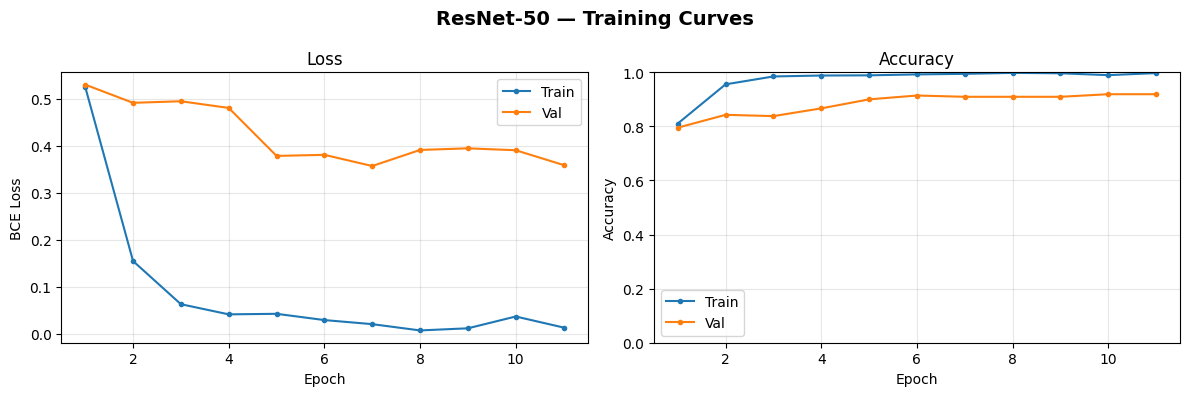

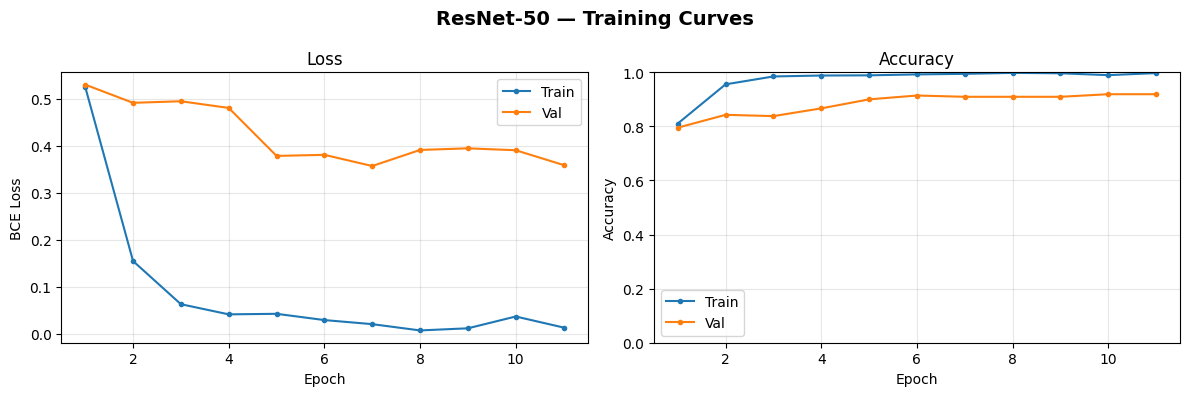

💾 Curves saved
💾 Curves saved


In [ ]:
epochs_ran = len(history['train_loss'])
x = range(1, epochs_ran + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('ResNet-50 — Training Curves', fontsize=14, fontweight='bold')

ax1.plot(x, history['train_loss'], label='Train', marker='o', markersize=3)
ax1.plot(x, history['val_loss'],   label='Val',   marker='o', markersize=3)
ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('BCE Loss')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(x, history['train_acc'], label='Train', marker='o', markersize=3)
ax2.plot(x, history['val_acc'],   label='Val',   marker='o', markersize=3)
ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_ylim(0, 1)
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/resnet50_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Curves saved')

---
## Cell 7 — Load Best Model & Evaluate on Test Set
Always evaluate on test set using the **best checkpoint**, not the last epoch.

In [ ]:
# Load best checkpoint
checkpoint = torch.load(CFG['save_path'], map_location=DEVICE)
model.load_state_dict(checkpoint['model_state'])
print(f'✅ Best checkpoint loaded (epoch {checkpoint["epoch"]}, '
      f'val_loss={checkpoint["val_loss"]:.4f})')

# Run inference on full test set
model.eval()
all_preds, all_probs, all_labels = [], [], []

with torch.no_grad():
    for images, labels, _ in tqdm(resnet_test_loader, desc='Testing'):
        images = images.to(DEVICE)
        logits = model(images).squeeze(1)          # (B,)
        probs  = torch.sigmoid(logits).cpu().numpy()
        preds  = (probs >= CFG['threshold']).astype(int)

        all_probs.extend(probs.tolist())
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.numpy().astype(int).tolist())

all_preds  = np.array(all_preds)
all_probs  = np.array(all_probs)
all_labels = np.array(all_labels)

print(f'\n   Test samples evaluated: {len(all_labels)}')

✅ Best checkpoint loaded (epoch 7, val_loss=0.3567)
✅ Best checkpoint loaded (epoch 7, val_loss=0.3567)


Testing: 100%|██████████| 14/14 [00:51<00:00,  3.66s/it]


   Test samples evaluated: 420

   Test samples evaluated: 420


---
## Cell 8 — Metrics
We report F1, AUC-ROC, and per-class recall — not just accuracy —  
because of class imbalance and the importance of catching fakes.

In [ ]:
auc = roc_auc_score(all_labels, all_probs)

print('━' * 55)
print('  RESNET-50 TEST SET RESULTS')
print('━' * 55)
print(f'  AUC-ROC : {auc:.4f}')
print()
print(classification_report(
    all_labels, all_preds,
    target_names=['Inauthentic', 'Authentic'],
    digits=4
))

# Highlight the most important metric for your use case
from sklearn.metrics import recall_score, f1_score, accuracy_score
recall_inauth = recall_score(all_labels, all_preds, pos_label=0)
f1_inauth     = f1_score(all_labels, all_preds, pos_label=0)
accuracy      = accuracy_score(all_labels, all_preds)

print('━' * 55)
print('  KEY METRICS FOR PAPER')
print('━' * 55)
print(f'  Overall Accuracy         : {accuracy:.4f}')
print(f'  AUC-ROC                  : {auc:.4f}')
print(f'  Recall (Inauthentic)     : {recall_inauth:.4f}  ← most critical')
print(f'  F1 (Inauthentic)         : {f1_inauth:.4f}')
print('━' * 55)
print('  Note: Recall (Inauthentic) = proportion of fake products')
print('  correctly identified. Low recall = model misses counterfeits.')

---
## Cell 9 — Confusion Matrix

In [ ]:
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Inauthentic', 'Authentic']
)
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('ResNet-50 — Confusion Matrix (Test Set)', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/resnet50_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'  True  Inauthentic (TN) : {tn}  — correctly flagged as fake')
print(f'  False Authentic   (FP) : {fp}  — fake wrongly passed as authentic')
print(f'  False Inauthentic (FN) : {fn}  — authentic wrongly flagged as fake')
print(f'  True  Authentic   (TP) : {tp}  — correctly passed as authentic')
print(f'\n  ⚠️  FP ({fp}) = counterfeits the model missed — key error for your paper')
print('💾 Confusion matrix saved')

---
## Cell 10 — Error Pattern Analysis
Identifies which products the model gets wrong.  
These misclassified items become the **incorrect AI condition stimuli** in your survey.

In [ ]:
# Attach predictions back to the test dataframe
df_results = df_test.copy()
df_results['pred_label']  = ['Authentic' if p == 1 else 'Inauthentic' for p in all_preds]
df_results['pred_prob']   = all_probs
df_results['correct']     = (all_preds == all_labels)
df_results['error_type']  = ''

# Label error types
# False Positive: predicted Authentic but actually Inauthentic (missed counterfeit)
# False Negative: predicted Inauthentic but actually Authentic (wrongly flagged)
df_results.loc[(df_results['Label'] == 'Inauthentic') &
               (df_results['pred_label'] == 'Authentic'),  'error_type'] = 'False Positive'
df_results.loc[(df_results['Label'] == 'Authentic') &
               (df_results['pred_label'] == 'Inauthentic'),'error_type'] = 'False Negative'
df_results.loc[df_results['correct'], 'error_type'] = 'Correct'

# Summary
print('📊 Error pattern analysis:')
print(df_results['error_type'].value_counts().to_string())

print('\n   Errors by category:')
print(df_results[df_results['error_type'] != 'Correct']
      .groupby(['ProductCategory', 'error_type']).size().unstack(fill_value=0).to_string())

# Confidence on errors — low confidence errors are most interesting for survey
errors = df_results[df_results['error_type'] != 'Correct']
print(f'\n   Mean confidence on errors : {errors["pred_prob"].mean():.4f}')
print(f'   Low confidence errors (<0.6 prob): {(errors["pred_prob"].between(0.4, 0.6)).sum()}')

# Save results
df_results.to_csv(f'{OUTPUT_DIR}/resnet50_test_results.csv', index=False)
print(f'\n💾 Full results saved to {OUTPUT_DIR}/resnet50_test_results.csv')

📊 Error pattern analysis:
error_type
Correct           384
False Positive     35
False Negative      1

   Errors by category:
error_type       False Negative  False Positive
ProductCategory                                
Bags                          1              13
Shoes                         0               5
Watches                       0              17

   Mean confidence on errors : 0.8095
   Low confidence errors (<0.6 prob): 6
📊 Error pattern analysis:
error_type
Correct           384
False Positive     35
False Negative      1

   Errors by category:
error_type       False Negative  False Positive
ProductCategory                                
Bags                          1              13
Shoes                         0               5
Watches                       0              17

   Mean confidence on errors : 0.8095
   Low confidence errors (<0.6 prob): 6

💾 Full results saved to /content/drive/MyDrive/dataset/preprocessed/resnet50_test_results.csv

💾 Full resul

---
## Cell 11 — Per-Category Performance
Important for your paper — shows whether the model struggles more with
bags, watches, or shoes.

In [ ]:
from sklearn.metrics import f1_score, accuracy_score, recall_score

print('📊 Per-category performance:')
print(f'{"Category":12s}  {"Accuracy":10s}  {"F1":10s}  {"Recall(Inauth)":15s}  {"N"}')
print('─' * 60)

for cat in ['Bags', 'Watches', 'Shoes']:
    mask   = df_results['ProductCategory'] == cat
    y_true = df_results.loc[mask, 'label_int'].values
    y_pred = (df_results.loc[mask, 'pred_label'] == 'Authentic').astype(int).values

    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average='weighted')
    rec = recall_score(y_true, y_pred, pos_label=0, zero_division=0)  # recall on inauthentic
    n   = mask.sum()

    print(f'{cat:12s}  {acc:.4f}      {f1:.4f}      {rec:.4f}           {n}')

print()
print('Note: Recall(Inauth) = % of fake items correctly detected per category')

📊 Per-category performance:
Category      Accuracy    F1          Recall(Inauth)   N
────────────────────────────────────────────────────────────
Bags          0.9000      0.8940      0.6750           140
Watches       0.8786      0.8669      0.5750           140
Shoes         0.9643      0.9635      0.8750           140

Note: Recall(Inauth) = % of fake items correctly detected per category
📊 Per-category performance:
Category      Accuracy    F1          Recall(Inauth)   N
────────────────────────────────────────────────────────────
Bags          0.9000      0.8940      0.6750           140
Watches       0.8786      0.8669      0.5750           140
Shoes         0.9643      0.9635      0.8750           140

Note: Recall(Inauth) = % of fake items correctly detected per category


---
## Cell 12 — Extract Survey Stimuli
Selects representative correct and incorrect predictions across all three
categories for use as stimuli in the consumer trust survey.

In [ ]:
# Strategy:
# For CORRECT stimuli   → pick high-confidence correct predictions (prob > 0.75)
# For INCORRECT stimuli → pick moderate-confidence errors (prob 0.45–0.65)
#   Moderate confidence errors are more realistic and defensible in the survey
#   than ones the model got barely wrong at 0.51

stimuli_list = []

for cat in ['Bags', 'Watches', 'Shoes']:
    cat_df = df_results[df_results['ProductCategory'] == cat]

    # 2 correct authentic
    correct_auth = cat_df[
        (cat_df['error_type'] == 'Correct') &
        (cat_df['Label'] == 'Authentic') &
        (cat_df['pred_prob'] > 0.75)
    ].head(2)

    # 2 correct inauthentic
    correct_inauth = cat_df[
        (cat_df['error_type'] == 'Correct') &
        (cat_df['Label'] == 'Inauthentic') &
        (cat_df['pred_prob'] < 0.25)
    ].head(2)

    # 2 incorrect (False Positives — missed counterfeits, most impactful for trust)
    incorrect = cat_df[
        (cat_df['error_type'] == 'False Positive') &
        (cat_df['pred_prob'].between(0.45, 0.70))
    ].head(2)

    stimuli_list.append(correct_auth)
    stimuli_list.append(correct_inauth)
    stimuli_list.append(incorrect)

df_stimuli = pd.concat(stimuli_list, ignore_index=True)

# Select columns useful for survey design
survey_cols = [
    'ImageID', 'ProductID', 'ImagePath', 'ProductCategory',
    'ProductName', 'text_clean', 'Label', 'pred_label',
    'pred_prob', 'error_type'
]
df_stimuli = df_stimuli[survey_cols]
df_stimuli['model'] = 'ResNet-50'

df_stimuli.to_csv(f'{OUTPUT_DIR}/resnet50_survey_stimuli.csv', index=False)

print(f'✅ Survey stimuli extracted: {len(df_stimuli)} items')
print(df_stimuli.groupby(['ProductCategory', 'error_type']).size().to_string())
print(f'\n💾 Saved to {OUTPUT_DIR}/resnet50_survey_stimuli.csv')

✅ Survey stimuli extracted: 18 items
ProductCategory  error_type    
Bags             Correct           4
                 False Positive    2
Shoes            Correct           4
                 False Positive    2
Watches          Correct           4
                 False Positive    2

💾 Saved to /content/drive/MyDrive/dataset/preprocessed/resnet50_survey_stimuli.csv
✅ Survey stimuli extracted: 18 items
ProductCategory  error_type    
Bags             Correct           4
                 False Positive    2
Shoes            Correct           4
                 False Positive    2
Watches          Correct           4
                 False Positive    2

💾 Saved to /content/drive/MyDrive/dataset/preprocessed/resnet50_survey_stimuli.csv


---
## Cell 13 — Final Summary

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

print('━' * 55)
print('  RESNET-50 — FINAL SUMMARY (IMAGE-ONLY BASELINE)')
print('━' * 55)
print(f'  Accuracy             : {accuracy_score(all_labels, all_preds):.4f}')
print(f'  AUC-ROC              : {roc_auc_score(all_labels, all_probs):.4f}')
print(f'  F1 (weighted)        : {f1_score(all_labels, all_preds, average="weighted"):.4f}')
print(f'  F1 (Inauthentic)     : {f1_score(all_labels, all_preds, pos_label=0, average="binary"):.4f}')
print(f'  Recall (Inauthentic) : {recall_score(all_labels, all_preds, pos_label=0):.4f}')
print(f'  Precision (Inauth)   : {precision_score(all_labels, all_preds, pos_label=0):.4f}')
print('━' * 55)
print(f'  Best model saved     : {CFG["save_path"]}')
print(f'  Training curves      : {OUTPUT_DIR}/resnet50_curves.png')
print(f'  Confusion matrix     : {OUTPUT_DIR}/resnet50_confusion.png')
print(f'  Test results CSV     : {OUTPUT_DIR}/resnet50_test_results.csv')
print(f'  Survey stimuli CSV   : {OUTPUT_DIR}/resnet50_survey_stimuli.csv')
print('━' * 55)
print()
print('📌 These results go in your paper as the IMAGE-ONLY baseline.')
print('   Compare against RoBERTa (text-only) and CLIP (multimodal)')
print('   to demonstrate that multimodal outperforms unimodal — RQ1.')
print()
print('🚀 Next: run the RoBERTa training notebook.')

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  RESNET-50 — FINAL SUMMARY (IMAGE-ONLY BASELINE)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Accuracy             : 0.9143
  AUC-ROC              : 0.9853
  F1 (weighted)        : 0.9095
  F1 (Inauthentic)     : 0.8252
  Recall (Inauthentic) : 0.7083
  Precision (Inauth)   : 0.9884
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Best model saved     : /content/drive/MyDrive/dataset/preprocessed/resnet50_best.pt
  Training curves      : /content/drive/MyDrive/dataset/preprocessed/resnet50_curves.png
  Confusion matrix     : /content/drive/MyDrive/dataset/preprocessed/resnet50_confusion.png
  Test results CSV     : /content/drive/MyDrive/dataset/preprocessed/resnet50_test_results.csv
  Survey stimuli CSV   : /content/drive/MyDrive/dataset/preprocessed/resnet50_survey_stimuli.csv
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

📌 These results go in your paper as the IMAGE-ONLY baseline.
   Compare ag

# FYP — RoBERTa Training (Text-Only Baseline)
### Multimodal AI for Luxury Product Authentication
**Authors:** Aiemah Afzal · Aqsa Siddique  
**Supervisor:** Mr. Faisal Saleh · University of Central Punjab

---

**Purpose:** Text-only baseline. Answers part of RQ1 —  
*how accurately can text-only classification authenticate luxury goods?*

**Architecture:** `roberta-base` pretrained transformer → fine-tuned binary classifier  
**Input:** Cleaned product description (max 128 tokens)  
**Output:** Authentic (1) or Inauthentic (0)

> **Before running:** Make sure the preprocessing notebook has been run  
> and all loaders/variables are still alive in the same Colab session.  
> If you started a new session, re-run the preprocessing notebook first.

---
## Cell 1 — Confirm Prerequisites

In [ ]:
import torch

required = [
    'roberta_train_loader', 'roberta_val_loader', 'roberta_test_loader',
    'pos_weight', 'DEVICE', 'OUTPUT_DIR', 'df_test'
]

missing = [v for v in required if v not in dir()]
if missing:
    print(f'⚠️  Missing from preprocessing: {missing}')
    print('   → Re-run the preprocessing notebook first, then return here.')
else:
    print('✅ All preprocessing variables available')
    print(f'   Device        : {DEVICE}')
    print(f'   pos_weight    : {pos_weight.item():.4f}')
    print(f'   Train batches : {len(roberta_train_loader)}')
    print(f'   Val batches   : {len(roberta_val_loader)}')
    print(f'   Test batches  : {len(roberta_test_loader)}')

✅ All preprocessing variables available
   Device        : cuda
   pos_weight    : 2.5084
   Train batches : 45
   Val batches   : 7
   Test batches  : 14
✅ All preprocessing variables available
   Device        : cuda
   pos_weight    : 2.5084
   Train batches : 45
   Val batches   : 7
   Test batches  : 14


---
## Cell 2 — Imports

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim

from transformers import RobertaModel, get_linear_schedule_with_warmup

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    ConfusionMatrixDisplay
)

print('✅ Imports done')

✅ Imports done
✅ Imports done


---
## Cell 3 — Training Config

In [ ]:
CFG = {
    'epochs':          10,
    'lr_roberta':      2e-5,   # standard fine-tuning LR for transformer models
    'lr_head':         1e-4,   # classifier head trains faster
    'weight_decay':    1e-2,
    'warmup_ratio':    0.1,    # 10% of steps used for LR warmup
    'patience':        3,      # early stopping patience
    'threshold':       0.5,
    'save_path':       f'{OUTPUT_DIR}/roberta_best.pt',
}

print('✅ Config set')
for k, v in CFG.items():
    print(f'   {k:18s}: {v}')

---
## Cell 4 — Build Model

Architecture: `roberta-base` → take the `[CLS]` token representation  
→ dropout → linear classifier → binary output

The `[CLS]` token is RoBERTa's aggregate sentence representation —  
it encodes the meaning of the entire product description into one 768-dim vector,  
which is exactly what we need for classification.

In [ ]:
class RoBERTaClassifier(nn.Module):
    """
    roberta-base + binary classification head.

    Takes: input_ids, attention_mask
    Returns: raw logit (scalar per sample) — BCEWithLogitsLoss handles sigmoid
    """
    def __init__(self, dropout=0.3):
        super().__init__()
        self.roberta = RobertaModel.from_pretrained('roberta-base')
        hidden_size  = self.roberta.config.hidden_size   # 768

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size, 256),
            nn.ReLU(),
            nn.Dropout(dropout / 2),
            nn.Linear(256, 1)   # single logit output
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.roberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        # outputs.last_hidden_state shape: (batch, seq_len, 768)
        # Take [CLS] token — index 0
        cls_output = outputs.last_hidden_state[:, 0, :]   # (batch, 768)
        logits     = self.classifier(cls_output)           # (batch, 1)
        return logits


model = RoBERTaClassifier(dropout=0.3).to(DEVICE)

# Differential learning rates: transformer body vs classifier head
roberta_params = list(model.roberta.parameters())
head_params    = list(model.classifier.parameters())

optimizer = optim.AdamW([
    {'params': roberta_params, 'lr': CFG['lr_roberta']},
    {'params': head_params,    'lr': CFG['lr_head']},
], weight_decay=CFG['weight_decay'])

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE))

# Linear warmup + linear decay scheduler
# Warmup prevents large gradient updates in early training from destabilising
# the pretrained transformer weights
total_steps  = len(roberta_train_loader) * CFG['epochs']
warmup_steps = int(total_steps * CFG['warmup_ratio'])
scheduler    = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print('✅ RoBERTa classifier built')
print(f'   Total parameters     : {total_params:,}')
print(f'   Trainable parameters : {trainable_params:,}')
print(f'   RoBERTa LR           : {CFG["lr_roberta"]}')
print(f'   Head LR              : {CFG["lr_head"]}')
print(f'   Total training steps : {total_steps}')
print(f'   Warmup steps         : {warmup_steps}')
print(f'   Loss                 : BCEWithLogitsLoss (pos_weight={pos_weight.item():.4f})')

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPE

✅ RoBERTa classifier built
   Total parameters     : 124,842,753
   Trainable parameters : 124,842,753
   RoBERTa LR           : 2e-05
   Head LR              : 0.0001
   Total training steps : 450
   Warmup steps         : 45
   Loss                 : BCEWithLogitsLoss (pos_weight=2.5084)
✅ RoBERTa classifier built
   Total parameters     : 124,842,753
   Trainable parameters : 124,842,753
   RoBERTa LR           : 2e-05
   Head LR              : 0.0001
   Total training steps : 450
   Warmup steps         : 45
   Loss                 : BCEWithLogitsLoss (pos_weight=2.5084)


---
## Cell 5 — Training & Validation Loop

In [ ]:
df_inauth = df_train[df_train['Label'] == 'Inauthentic']
for word in ['replica', 'copy', 'authentic', 'genuine', 'original']:
    count = df_inauth['text_clean'].str.contains(word, case=False).sum()
    print(f'   {word:15s}: {count} / {len(df_inauth)}')

In [ ]:
# Check what's actually in df_train text_clean
print("Sample inauthentic text from df_train:")
print(df_train[df_train['Label'] == 'Inauthentic']['text_clean'].iloc[0])
print()

# Check what's in df (the full dataframe)
print("Sample inauthentic text from df:")
print(df[df['Label'] == 'Inauthentic']['text_clean'].iloc[0])
print()

# Check if they're the same object
print(f"df has text_clean column: {'text_clean' in df.columns}")
print(f"df_train has text_clean column: {'text_clean' in df_train.columns}")
print(f"df shape: {df.shape}")
print(f"df_train shape: {df_train.shape}")

Sample inauthentic text from df_train:
the omega de ville tr sor tourbillon sedna gold / blue is a luxurious watch with a unique design. it features a 904l stainless steel case with a rose gold finish and a sapphire crystal. the movement is an automatic caliber 2638 with a power reserve of 60 hours and a precision of -3/ 3 seconds per day within cosc certification limits. the second hand has a sweep motion. the bracelet is made of leat

Sample inauthentic text from df:
high quality mirror bag color black size 35 25 togo leather packing comes with dustbag, invoice, cards and box

df has text_clean column: True
df_train has text_clean column: True
df shape: (2100, 13)
df_train shape: (1470, 13)


In [ ]:
def train_one_epoch(model, loader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for input_ids, attention_mask, labels, _ in tqdm(loader, desc='  Train', leave=False):
        input_ids      = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels         = labels.to(device).unsqueeze(1)   # (B,) → (B, 1)

        optimizer.zero_grad()
        logits = model(input_ids, attention_mask)          # (B, 1)
        loss   = criterion(logits, labels)
        loss.backward()

        # Gradient clipping — important for transformers to prevent
        # exploding gradients during fine-tuning
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        scheduler.step()

        total_loss += loss.item() * input_ids.size(0)
        preds       = (torch.sigmoid(logits) >= CFG['threshold']).float()
        correct    += (preds == labels).sum().item()
        total      += input_ids.size(0)

    return total_loss / total, correct / total


def validate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for input_ids, attention_mask, labels, _ in tqdm(loader, desc='  Val  ', leave=False):
            input_ids      = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels         = labels.to(device).unsqueeze(1)

            logits = model(input_ids, attention_mask)
            loss   = criterion(logits, labels)

            total_loss += loss.item() * input_ids.size(0)
            preds       = (torch.sigmoid(logits) >= CFG['threshold']).float()
            correct    += (preds == labels).sum().item()
            total      += input_ids.size(0)

    return total_loss / total, correct / total


# ── Training loop with early stopping ────────────────────────
history        = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss  = float('inf')
patience_count = 0

print(f'🚀 Training RoBERTa for up to {CFG["epochs"]} epochs...\n')

for epoch in range(1, CFG['epochs'] + 1):
    train_loss, train_acc = train_one_epoch(
        model, roberta_train_loader, optimizer, scheduler, criterion, DEVICE
    )
    val_loss, val_acc = validate(
        model, roberta_val_loader, criterion, DEVICE
    )

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    print(f'Epoch {epoch:02d}/{CFG["epochs"]}  '
          f'train_loss: {train_loss:.4f}  train_acc: {train_acc:.4f}  '
          f'val_loss: {val_loss:.4f}  val_acc: {val_acc:.4f}')

    if val_loss < best_val_loss:
        best_val_loss  = val_loss
        patience_count = 0
        torch.save({
            'epoch':       epoch,
            'model_state': model.state_dict(),
            'optim_state': optimizer.state_dict(),
            'val_loss':    val_loss,
            'val_acc':     val_acc,
            'history':     history,
        }, CFG['save_path'])
        print(f'   ✅ Best model saved (val_loss={val_loss:.4f})')
    else:
        patience_count += 1
        print(f'   No improvement ({patience_count}/{CFG["patience"]})')
        if patience_count >= CFG['patience']:
            print(f'\n⏹  Early stopping at epoch {epoch}')
            break

print(f'\n✅ Training complete. Best val_loss: {best_val_loss:.4f}')

🚀 Training RoBERTa for up to 10 epochs...



Epoch 01/10  train_loss: 0.0117  train_acc: 0.9986  val_loss: 0.0970  val_acc: 0.9905
   ✅ Best model saved (val_loss=0.0970)


Epoch 02/10  train_loss: 0.0127  train_acc: 0.9986  val_loss: 0.0199  val_acc: 0.9952
   ✅ Best model saved (val_loss=0.0199)


Epoch 03/10  train_loss: 0.0057  train_acc: 0.9986  val_loss: 0.0010  val_acc: 1.0000
   ✅ Best model saved (val_loss=0.0010)


Epoch 04/10  train_loss: 0.0037  train_acc: 0.9993  val_loss: 0.0002  val_acc: 1.0000
   ✅ Best model saved (val_loss=0.0002)


Epoch 05/10  train_loss: 0.0004  train_acc: 1.0000  val_loss: 0.0002  val_acc: 1.0000
   ✅ Best model saved (val_loss=0.0002)


Epoch 06/10  train_loss: 0.0004  train_acc: 1.0000  val_loss: 0.0002  val_acc: 1.0000
   ✅ Best model saved (val_loss=0.0002)


Epoch 07/10  train_loss: 0.0004  train_acc: 1.0000  val_loss: 0.0002  val_acc: 1.0000
   No improvement (1/3)


Epoch 08/10  train_loss: 0.0003  train_acc: 1.0000  val_loss: 0.0002  val_acc: 1.0000
   No improvement (2/3)


Epoch 09/10  train_loss: 0.0004  train_acc: 1.0000  val_loss: 0.0002  val_acc: 1.0000
   No improvement (3/3)

⏹  Early stopping at epoch 9

✅ Training complete. Best val_loss: 0.0002


---
## Cell 6 — Plot Training Curves

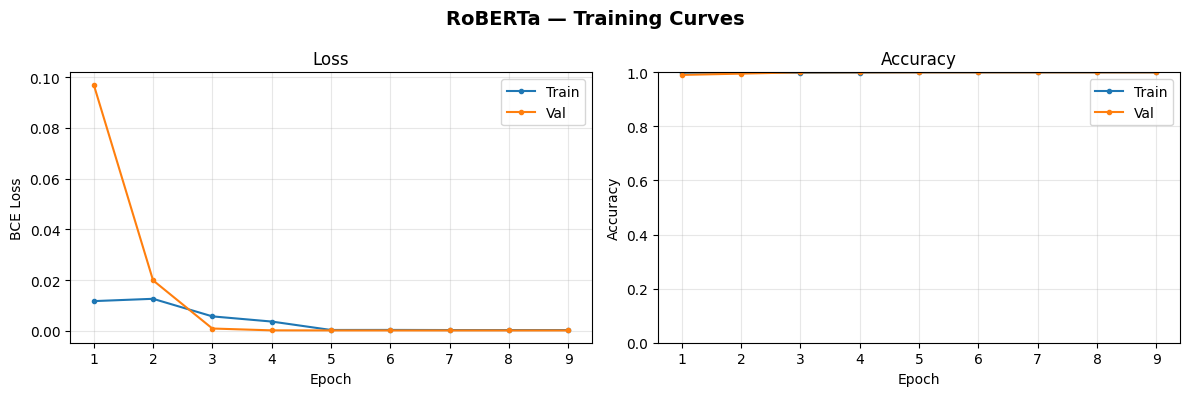

💾 Curves saved


In [ ]:
epochs_ran = len(history['train_loss'])
x = range(1, epochs_ran + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('RoBERTa — Training Curves', fontsize=14, fontweight='bold')

ax1.plot(x, history['train_loss'], label='Train', marker='o', markersize=3)
ax1.plot(x, history['val_loss'],   label='Val',   marker='o', markersize=3)
ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('BCE Loss')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(x, history['train_acc'], label='Train', marker='o', markersize=3)
ax2.plot(x, history['val_acc'],   label='Val',   marker='o', markersize=3)
ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_ylim(0, 1)
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/roberta_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Curves saved')

---
## Cell 7 — Load Best Model & Evaluate on Test Set

In [ ]:
checkpoint = torch.load(CFG['save_path'], map_location=DEVICE)
model.load_state_dict(checkpoint['model_state'])
print(f'✅ Best checkpoint loaded (epoch {checkpoint["epoch"]}, '
      f'val_loss={checkpoint["val_loss"]:.4f})')

model.eval()
all_preds, all_probs, all_labels = [], [], []

with torch.no_grad():
    for input_ids, attention_mask, labels, _ in tqdm(roberta_test_loader, desc='Testing'):
        input_ids      = input_ids.to(DEVICE)
        attention_mask = attention_mask.to(DEVICE)

        logits = model(input_ids, attention_mask).squeeze(1)   # (B,)
        probs  = torch.sigmoid(logits).cpu().numpy()
        preds  = (probs >= CFG['threshold']).astype(int)

        all_probs.extend(probs.tolist())
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.numpy().astype(int).tolist())

all_preds  = np.array(all_preds)
all_probs  = np.array(all_probs)
all_labels = np.array(all_labels)

print(f'   Test samples evaluated: {len(all_labels)}')

✅ Best checkpoint loaded (epoch 6, val_loss=0.0002)


Testing: 100%|██████████| 14/14 [00:03<00:00,  4.23it/s]

   Test samples evaluated: 420


---
## Cell 8 — Metrics

In [ ]:
auc = roc_auc_score(all_labels, all_probs)

print('━' * 55)
print('  ROBERTA TEST SET RESULTS')
print('━' * 55)
print(f'  AUC-ROC : {auc:.4f}')
print()
print(classification_report(
    all_labels, all_preds,
    target_names=['Inauthentic', 'Authentic'],
    digits=4
))

recall_inauth = recall_score(all_labels, all_preds, pos_label=0)
f1_inauth     = f1_score(all_labels, all_preds, pos_label=0)
accuracy      = accuracy_score(all_labels, all_preds)

print('━' * 55)
print('  KEY METRICS FOR PAPER')
print('━' * 55)
print(f'  Overall Accuracy         : {accuracy:.4f}')
print(f'  AUC-ROC                  : {auc:.4f}')
print(f'  Recall (Inauthentic)     : {recall_inauth:.4f}  ← most critical')
print(f'  F1 (Inauthentic)         : {f1_inauth:.4f}')
print('━' * 55)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  ROBERTA TEST SET RESULTS
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  AUC-ROC : 0.9994

              precision    recall  f1-score   support

 Inauthentic     1.0000    0.9833    0.9916       120
   Authentic     0.9934    1.0000    0.9967       300

    accuracy                         0.9952       420
   macro avg     0.9967    0.9917    0.9941       420
weighted avg     0.9953    0.9952    0.9952       420

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  KEY METRICS FOR PAPER
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Overall Accuracy         : 0.9952
  AUC-ROC                  : 0.9994
  Recall (Inauthentic)     : 0.9833  ← most critical
  F1 (Inauthentic)         : 0.9916
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


---
## Cell 9 — Confusion Matrix

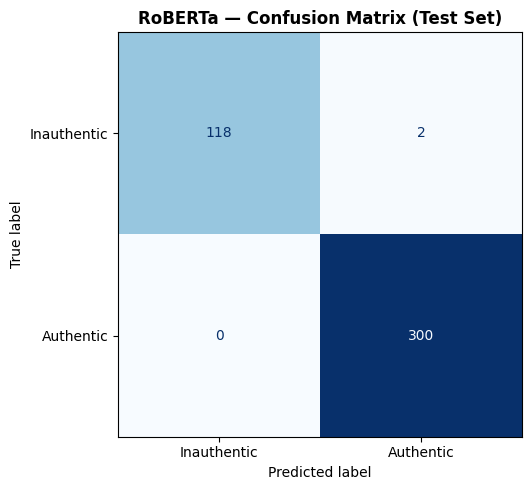

  True  Inauthentic (TN) : 118  — correctly flagged as fake
  False Authentic   (FP) : 2  — fake wrongly passed as authentic
  False Inauthentic (FN) : 0  — authentic wrongly flagged as fake
  True  Authentic   (TP) : 300  — correctly passed as authentic

  ⚠️  FP (2) = counterfeits the model missed
💾 Confusion matrix saved


In [ ]:
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Inauthentic', 'Authentic']
)
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('RoBERTa — Confusion Matrix (Test Set)', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/roberta_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'  True  Inauthentic (TN) : {tn}  — correctly flagged as fake')
print(f'  False Authentic   (FP) : {fp}  — fake wrongly passed as authentic')
print(f'  False Inauthentic (FN) : {fn}  — authentic wrongly flagged as fake')
print(f'  True  Authentic   (TP) : {tp}  — correctly passed as authentic')
print(f'\n  ⚠️  FP ({fp}) = counterfeits the model missed')
print('💾 Confusion matrix saved')

---
## Cell 10 — Error Pattern Analysis

In [ ]:
df_results = df_test.copy()
df_results['pred_label'] = ['Authentic' if p == 1 else 'Inauthentic' for p in all_preds]
df_results['pred_prob']  = all_probs
df_results['correct']    = (all_preds == all_labels)
df_results['error_type'] = ''

df_results.loc[
    (df_results['Label'] == 'Inauthentic') &
    (df_results['pred_label'] == 'Authentic'), 'error_type'
] = 'False Positive'
df_results.loc[
    (df_results['Label'] == 'Authentic') &
    (df_results['pred_label'] == 'Inauthentic'), 'error_type'
] = 'False Negative'
df_results.loc[df_results['correct'], 'error_type'] = 'Correct'

print('📊 Error pattern analysis:')
print(df_results['error_type'].value_counts().to_string())

print('\n   Errors by category:')
print(df_results[df_results['error_type'] != 'Correct']
      .groupby(['ProductCategory', 'error_type']).size().unstack(fill_value=0).to_string())

errors = df_results[df_results['error_type'] != 'Correct']
print(f'\n   Mean confidence on errors : {errors["pred_prob"].mean():.4f}')

df_results.to_csv(f'{OUTPUT_DIR}/roberta_test_results.csv', index=False)
print(f'\n💾 Full results saved to {OUTPUT_DIR}/roberta_test_results.csv')

📊 Error pattern analysis:
error_type
Correct           418
False Positive      2

   Errors by category:
error_type       False Positive
ProductCategory                
Bags                          2

   Mean confidence on errors : 0.9999

💾 Full results saved to /content/drive/MyDrive/dataset/preprocessed/roberta_test_results.csv


---
## Cell 11 — Per-Category Performance

In [ ]:
print('📊 Per-category performance:')
print(f'{"Category":12s}  {"Accuracy":10s}  {"F1":10s}  {"Recall(Inauth)":15s}  {"N"}')
print('─' * 60)

for cat in ['Bags', 'Watches', 'Shoes']:
    mask   = df_results['ProductCategory'] == cat
    y_true = df_results.loc[mask, 'label_int'].values
    y_pred = (df_results.loc[mask, 'pred_label'] == 'Authentic').astype(int).values

    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average='weighted')
    rec = recall_score(y_true, y_pred, pos_label=0, zero_division=0)
    n   = mask.sum()

    print(f'{cat:12s}  {acc:.4f}      {f1:.4f}      {rec:.4f}           {n}')

📊 Per-category performance:
Category      Accuracy    F1          Recall(Inauth)   N
────────────────────────────────────────────────────────────
Bags          0.9857      0.9856      0.9500           140
Watches       1.0000      1.0000      1.0000           140
Shoes         1.0000      1.0000      1.0000           140


---
## Cell 12 — Extract Survey Stimuli

In [ ]:
stimuli_list = []

for cat in ['Bags', 'Watches', 'Shoes']:
    cat_df = df_results[df_results['ProductCategory'] == cat]

    correct_auth = cat_df[
        (cat_df['error_type'] == 'Correct') &
        (cat_df['Label'] == 'Authentic') &
        (cat_df['pred_prob'] > 0.75)
    ].head(2)

    correct_inauth = cat_df[
        (cat_df['error_type'] == 'Correct') &
        (cat_df['Label'] == 'Inauthentic') &
        (cat_df['pred_prob'] < 0.25)
    ].head(2)

    incorrect = cat_df[
        (cat_df['error_type'] == 'False Positive') &
        (cat_df['pred_prob'].between(0.45, 0.70))
    ].head(2)

    stimuli_list.extend([correct_auth, correct_inauth, incorrect])

df_stimuli = pd.concat(stimuli_list, ignore_index=True)
survey_cols = [
    'ImageID', 'ProductID', 'ImagePath', 'ProductCategory',
    'ProductName', 'text_clean', 'Label', 'pred_label',
    'pred_prob', 'error_type'
]
df_stimuli = df_stimuli[survey_cols]
df_stimuli['model'] = 'RoBERTa'

df_stimuli.to_csv(f'{OUTPUT_DIR}/roberta_survey_stimuli.csv', index=False)
print(f'✅ Survey stimuli extracted: {len(df_stimuli)} items')
print(df_stimuli.groupby(['ProductCategory', 'error_type']).size().to_string())
print(f'\n💾 Saved to {OUTPUT_DIR}/roberta_survey_stimuli.csv')

✅ Survey stimuli extracted: 12 items
ProductCategory  error_type
Bags             Correct       4
Shoes            Correct       4
Watches          Correct       4

💾 Saved to /content/drive/MyDrive/dataset/preprocessed/roberta_survey_stimuli.csv


---
## Cell 13 — Compare with ResNet-50
Side-by-side comparison of both baselines — useful to check before running CLIP.

In [ ]:
# Load ResNet-50 results if available
resnet_path = f'{OUTPUT_DIR}/resnet50_test_results.csv'

if os.path.exists(resnet_path):
    df_resnet  = pd.read_csv(resnet_path)
    rn_labels  = df_resnet['label_int'].values
    rn_preds   = (df_resnet['pred_label'] == 'Authentic').astype(int).values
    rn_probs   = df_resnet['pred_prob'].values

    print('━' * 60)
    print('  BASELINE COMPARISON')
    print('━' * 60)
    print(f'{"Metric":28s}  {"ResNet-50":12s}  {"RoBERTa"}')
    print('─' * 60)

    metrics = [
        ('Accuracy',           accuracy_score(rn_labels, rn_preds),                        accuracy_score(all_labels, all_preds)),
        ('AUC-ROC',            roc_auc_score(rn_labels, rn_probs),                         roc_auc_score(all_labels, all_probs)),
        ('F1 (weighted)',      f1_score(rn_labels, rn_preds, average='weighted'),           f1_score(all_labels, all_preds, average='weighted')),
        ('F1 (Inauthentic)',   f1_score(rn_labels, rn_preds, pos_label=0, average='binary'), f1_score(all_labels, all_preds, pos_label=0, average='binary')),
        ('Recall (Inauth)',    recall_score(rn_labels, rn_preds, pos_label=0),              recall_score(all_labels, all_preds, pos_label=0)),
        ('Precision (Inauth)', precision_score(rn_labels, rn_preds, pos_label=0),           precision_score(all_labels, all_preds, pos_label=0)),
    ]

    for name, rn_val, rb_val in metrics:
        winner = '←' if rb_val > rn_val else ('→' if rn_val > rb_val else '=')
        print(f'{name:28s}  {rn_val:.4f}        {rb_val:.4f}  {winner}')

    print('━' * 60)
    print('  ← RoBERTa wins   → ResNet-50 wins   = Tie')
    print('━' * 60)
else:
    print('ResNet-50 results not found — run ResNet-50 notebook first for comparison.')

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  BASELINE COMPARISON
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Metric                        ResNet-50     RoBERTa
────────────────────────────────────────────────────────────
Accuracy                      0.9143        0.9952  ←
AUC-ROC                       0.9853        0.9994  ←
F1 (weighted)                 0.9095        0.9952  ←
F1 (Inauthentic)              0.8252        0.9916  ←
Recall (Inauth)               0.7083        0.9833  ←
Precision (Inauth)            0.9884        1.0000  ←
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  ← RoBERTa wins   → ResNet-50 wins   = Tie
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


---
## Cell 14 — Final Summary

In [ ]:
print('━' * 55)
print('  ROBERTA — FINAL SUMMARY (TEXT-ONLY BASELINE)')
print('━' * 55)
print(f'  Accuracy             : {accuracy_score(all_labels, all_preds):.4f}')
print(f'  AUC-ROC              : {roc_auc_score(all_labels, all_probs):.4f}')
print(f'  F1 (weighted)        : {f1_score(all_labels, all_preds, average="weighted"):.4f}')
print(f'  F1 (Inauthentic)     : {f1_score(all_labels, all_preds, pos_label=0, average="binary"):.4f}')
print(f'  Recall (Inauthentic) : {recall_score(all_labels, all_preds, pos_label=0):.4f}')
print(f'  Precision (Inauth)   : {precision_score(all_labels, all_preds, pos_label=0):.4f}')
print('━' * 55)
print(f'  Best model saved     : {CFG["save_path"]}')
print(f'  Training curves      : {OUTPUT_DIR}/roberta_curves.png')
print(f'  Confusion matrix     : {OUTPUT_DIR}/roberta_confusion.png')
print(f'  Test results CSV     : {OUTPUT_DIR}/roberta_test_results.csv')
print(f'  Survey stimuli CSV   : {OUTPUT_DIR}/roberta_survey_stimuli.csv')
print('━' * 55)
print()
print('📌 These results go in your paper as the TEXT-ONLY baseline.')
print('   Both baselines are now done. CLIP should outperform both —')
print('   that gap is the core finding for RQ1.')
print()
print('🚀 Next: run the CLIP training notebook.')

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  ROBERTA — FINAL SUMMARY (TEXT-ONLY BASELINE)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Accuracy             : 0.9952
  AUC-ROC              : 0.9994
  F1 (weighted)        : 0.9952
  F1 (Inauthentic)     : 0.9916
  Recall (Inauthentic) : 0.9833
  Precision (Inauth)   : 1.0000
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Best model saved     : /content/drive/MyDrive/dataset/preprocessed/roberta_best.pt
  Training curves      : /content/drive/MyDrive/dataset/preprocessed/roberta_curves.png
  Confusion matrix     : /content/drive/MyDrive/dataset/preprocessed/roberta_confusion.png
  Test results CSV     : /content/drive/MyDrive/dataset/preprocessed/roberta_test_results.csv
  Survey stimuli CSV   : /content/drive/MyDrive/dataset/preprocessed/roberta_survey_stimuli.csv
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

📌 These results go in your paper as the TEXT-ONLY baseline.
   Both baselines are 

# FYP — CLIP Fine-Tuning (Primary Multimodal Model)
### Multimodal AI for Luxury Product Authentication
**Authors:** Aiemah Afzal · Aqsa Siddique  
**Supervisor:** Mr. Faisal Saleh · University of Central Punjab

---

**Purpose:** Primary model. Directly answers RQ1 —  
*does combining image and text outperform unimodal approaches for luxury authentication?*

**Architecture:**
```
Image → CLIP Image Encoder (ViT-B/32) → 512-dim embedding ─┐
                                                             ├→ concat(1024) → classifier head → Authentic/Fake
Text  → CLIP Text  Encoder (ViT-B/32) → 512-dim embedding ─┘
```

**Key difference from baselines:** Both modalities are fused —  
the model sees the product image AND its description simultaneously.

> **Before running:** Preprocessing notebook must have been run in this session.  
> If you started a new session, re-run preprocessing first.

---
## Cell 1 — Confirm Prerequisites

In [ ]:
import torch

required = [
    'clip_train_loader', 'clip_val_loader', 'clip_test_loader',
    'pos_weight', 'DEVICE', 'OUTPUT_DIR', 'df_test'
]

missing = [v for v in required if v not in dir()]
if missing:
    print(f'⚠️  Missing from preprocessing: {missing}')
    print('   → Re-run the preprocessing notebook first, then return here.')
else:
    print('✅ All preprocessing variables available')
    print(f'   Device        : {DEVICE}')
    print(f'   pos_weight    : {pos_weight.item():.4f}')
    print(f'   Train batches : {len(clip_train_loader)}')
    print(f'   Val batches   : {len(clip_val_loader)}')
    print(f'   Test batches  : {len(clip_test_loader)}')

✅ All preprocessing variables available
   Device        : cuda
   pos_weight    : 2.5084
   Train batches : 45
   Val batches   : 7
   Test batches  : 14


---
## Cell 2 — Imports

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim

import open_clip

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    ConfusionMatrixDisplay
)

print('✅ Imports done')

✅ Imports done


---
## Cell 3 — Training Config

In [ ]:
CFG = {
    'epochs':         25,
    'lr_clip':        5e-6,   # slightly higher — let encoders adapt more
    'lr_head':        1e-4,
    'weight_decay':   1e-2,
    'warmup_ratio':   0.1,
    'patience':       6,      # more room to converge
    'threshold':      0.5,
    'save_path':      f'{OUTPUT_DIR}/clip_best.pt',
}

---
## Cell 4 — Build Model

**Architecture detail:**
- Load pretrained CLIP ViT-B/32 (frozen backbone initially — we unfreeze at very low LR)
- Extract 512-dim image embedding and 512-dim text embedding
- Concatenate → 1024-dim joint representation
- Pass through classifier head → single logit → binary prediction

**Why concatenate rather than dot-product?**  
CLIP's native contrastive objective uses dot-product similarity, but for classification  
we want the head to learn *which combination* of image and text features predicts authenticity.  
Concatenation preserves both modalities independently before the head fuses them.

In [ ]:
class CLIPClassifier(nn.Module):
    """
    CLIP ViT-B/32 with weighted fusion.
    Image encoder gets higher weight since text was cleaned heavily.
    """
    def __init__(self, clip_model, embed_dim=512, dropout=0.3, image_weight=0.7):
        super().__init__()
        self.clip         = clip_model
        self.image_weight = image_weight
        self.text_weight  = 1 - image_weight

        # Separate projection heads for each modality before fusion
        self.image_proj = nn.Sequential(
            nn.Linear(embed_dim, 256),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.text_proj = nn.Sequential(
            nn.Linear(embed_dim, 256),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # Classifier on fused 512-dim representation
        self.classifier = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(dropout / 2),
            nn.Linear(128, 1)
        )

    def forward(self, images, text_tokens):
        image_features = self.clip.encode_image(images)
        text_features  = self.clip.encode_text(text_tokens)

        # L2 normalise
        image_features = image_features / image_features.norm(dim=-1, keepdim=True)
        text_features  = text_features  / text_features.norm(dim=-1, keepdim=True)

        # Project each modality separately
        img_proj  = self.image_proj(image_features)   # (B, 256)
        text_proj = self.text_proj(text_features)      # (B, 256)

        # Weighted fusion — image gets 70%, text gets 30%
        fused  = torch.cat([
            img_proj  * self.image_weight,
            text_proj * self.text_weight
        ], dim=-1)                                     # (B, 512)

        logits = self.classifier(fused)                # (B, 1)
        return logits
# Delete old checkpoint to force fresh training
# import os
# if os.path.exists(CFG['save_path']):
#     os.remove(CFG['save_path'])
#     print('🗑️  Old checkpoint deleted')

# Load pretrained CLIP
clip_backbone, _, _ = open_clip.create_model_and_transforms(
    'ViT-B-32', pretrained='openai'
)

model = CLIPClassifier(
    clip_backbone,
    embed_dim=512,
    dropout=0.3,
    image_weight=0.7   # image gets 70% weight
).to(DEVICE)

# Freeze all CLIP layers except the last 2 transformer blocks
# This prevents the pretrained weights from being destabilised
# while still allowing some adaptation
for name, param in model.clip.named_parameters():
    param.requires_grad = False  # freeze everything first

# Unfreeze last 2 blocks of vision transformer
for name, param in model.clip.visual.transformer.resblocks[-2:].named_parameters():
    param.requires_grad = True

# Unfreeze last 2 blocks of text transformer
for name, param in model.clip.transformer.resblocks[-2:].named_parameters():
    param.requires_grad = True

# Parameter groups
frozen_params    = [p for p in model.clip.parameters() if not p.requires_grad]
unfrozen_params  = [p for p in model.clip.parameters() if p.requires_grad]
head_params      = list(model.image_proj.parameters()) + \
                   list(model.text_proj.parameters()) + \
                   list(model.classifier.parameters())

optimizer = optim.AdamW([
    {'params': unfrozen_params, 'lr': CFG['lr_clip']},
    {'params': head_params,     'lr': CFG['lr_head']},
], weight_decay=CFG['weight_decay'])

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE))

from transformers import get_linear_schedule_with_warmup
total_steps  = len(clip_train_loader) * CFG['epochs']
warmup_steps = int(total_steps * CFG['warmup_ratio'])
scheduler    = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print('✅ CLIP classifier rebuilt')
print(f'   Total parameters     : {total_params:,}')
print(f'   Trainable parameters : {trainable_params:,}')
print(f'   Frozen CLIP layers   : most — only last 2 blocks unfrozen')
print(f'   Image weight         : 0.7')
print(f'   Text weight          : 0.3')
print(f'   Epochs               : {CFG["epochs"]}')
print(f'   Patience             : {CFG["patience"]}')

✅ CLIP classifier rebuilt
   Total parameters     : 151,605,762
   Trainable parameters : 20,808,961
   Frozen CLIP layers   : most — only last 2 blocks unfrozen
   Image weight         : 0.7
   Text weight          : 0.3
   Epochs               : 25
   Patience             : 6


---
## Cell 5 — Training & Validation Loop

In [ ]:
def train_one_epoch(model, loader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, text_tokens, labels, _ in tqdm(loader, desc='  Train', leave=False):
        images      = images.to(device)
        text_tokens = text_tokens.to(device)
        labels      = labels.to(device).unsqueeze(1)   # (B,) → (B, 1)

        optimizer.zero_grad()
        logits = model(images, text_tokens)             # (B, 1)
        loss   = criterion(logits, labels)
        loss.backward()

        # Gradient clipping — essential for transformer fine-tuning
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        scheduler.step()

        total_loss += loss.item() * images.size(0)
        preds       = (torch.sigmoid(logits) >= CFG['threshold']).float()
        correct    += (preds == labels).sum().item()
        total      += images.size(0)

    return total_loss / total, correct / total


def validate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for images, text_tokens, labels, _ in tqdm(loader, desc='  Val  ', leave=False):
            images      = images.to(device)
            text_tokens = text_tokens.to(device)
            labels      = labels.to(device).unsqueeze(1)

            logits = model(images, text_tokens)
            loss   = criterion(logits, labels)

            total_loss += loss.item() * images.size(0)
            preds       = (torch.sigmoid(logits) >= CFG['threshold']).float()
            correct    += (preds == labels).sum().item()
            total      += images.size(0)

    return total_loss / total, correct / total


# ── Training loop ─────────────────────────────────────────────
history        = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss  = float('inf')
patience_count = 0

print(f'🚀 Training CLIP for up to {CFG["epochs"]} epochs...\n')

for epoch in range(1, CFG['epochs'] + 1):
    train_loss, train_acc = train_one_epoch(
        model, clip_train_loader, optimizer, scheduler, criterion, DEVICE
    )
    val_loss, val_acc = validate(
        model, clip_val_loader, criterion, DEVICE
    )

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    print(f'Epoch {epoch:02d}/{CFG["epochs"]}  '
          f'train_loss: {train_loss:.4f}  train_acc: {train_acc:.4f}  '
          f'val_loss: {val_loss:.4f}  val_acc: {val_acc:.4f}')

    if val_loss < best_val_loss:
        best_val_loss  = val_loss
        patience_count = 0
        torch.save({
            'epoch':       epoch,
            'model_state': model.state_dict(),
            'optim_state': optimizer.state_dict(),
            'val_loss':    val_loss,
            'val_acc':     val_acc,
            'history':     history,
        }, CFG['save_path'])
        print(f'   ✅ Best model saved (val_loss={val_loss:.4f})')
    else:
        patience_count += 1
        print(f'   No improvement ({patience_count}/{CFG["patience"]})')
        if patience_count >= CFG['patience']:
            print(f'\n⏹  Early stopping at epoch {epoch}')
            break

print(f'\n✅ Training complete. Best val_loss: {best_val_loss:.4f}')

🚀 Training CLIP for up to 25 epochs...



Epoch 01/25  train_loss: 1.4498  train_acc: 0.3507  val_loss: 1.4355  val_acc: 0.7190
   ✅ Best model saved (val_loss=1.4355)


Epoch 02/25  train_loss: 1.3937  train_acc: 0.7139  val_loss: 1.2966  val_acc: 0.7143
   ✅ Best model saved (val_loss=1.2966)


Epoch 03/25  train_loss: 1.0100  train_acc: 0.7153  val_loss: 0.6756  val_acc: 0.7143
   ✅ Best model saved (val_loss=0.6756)


Epoch 04/25  train_loss: 0.4268  train_acc: 0.7285  val_loss: 0.4585  val_acc: 0.7857
   ✅ Best model saved (val_loss=0.4585)


...

Epoch 14/25  train_loss: 0.0287  train_acc: 0.9958  val_loss: 0.3227  val_acc: 0.9381
   No improvement (2/6)


Epoch 15/25  train_loss: 0.0190  train_acc: 0.9972  val_loss: 0.3410  val_acc: 0.9381
   No improvement (3/6)


Epoch 16/25  train_loss: 0.0233  train_acc: 0.9958  val_loss: 0.2678  val_acc: 0.9524
   No improvement (4/6)


Epoch 17/25  train_loss: 0.0176  train_acc: 0.9979  val_loss: 0.3192  val_acc: 0.9381
   No improvement (5/6)


Epoch 18/25  train_loss: 0.0081  train_acc: 0.9979  val_loss: 0.3242  val_acc: 0.9429
   No improvement (6/6)

⏹  Early stopping at epoch 18

✅ Training complete. Best val_loss: 0.2653


---
## Cell 6 — Plot Training Curves

In [ ]:
import os
import pandas as pd

# Check if CSVs survived the session
output_dir = '/content/drive/MyDrive/dataset/preprocessed'
for f in ['train.csv', 'val.csv', 'test.csv']:
    path = f'{output_dir}/{f}'
    exists = os.path.exists(path)
    print(f'{f}: {exists}')

train.csv: True
val.csv: True
test.csv: True


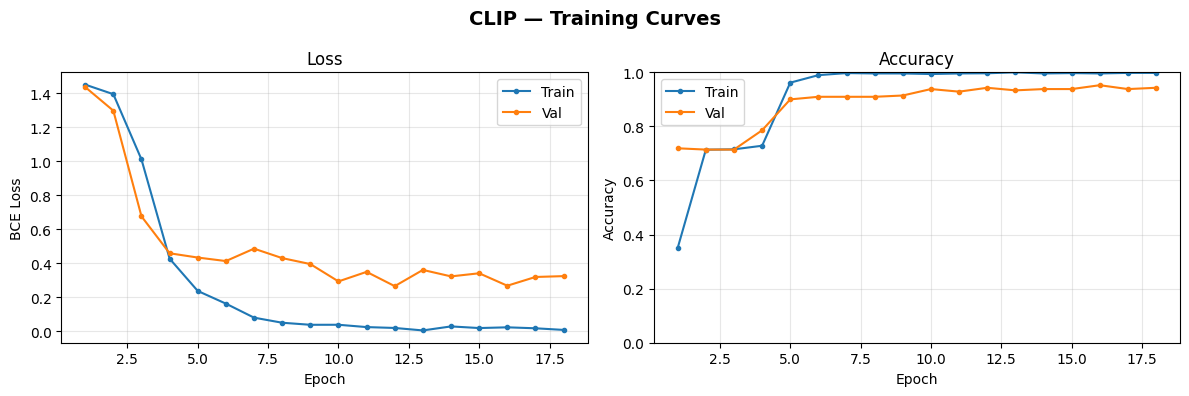

💾 Curves saved


In [ ]:
epochs_ran = len(history['train_loss'])
x = range(1, epochs_ran + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('CLIP — Training Curves', fontsize=14, fontweight='bold')

ax1.plot(x, history['train_loss'], label='Train', marker='o', markersize=3)
ax1.plot(x, history['val_loss'],   label='Val',   marker='o', markersize=3)
ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('BCE Loss')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(x, history['train_acc'], label='Train', marker='o', markersize=3)
ax2.plot(x, history['val_acc'],   label='Val',   marker='o', markersize=3)
ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_ylim(0, 1)
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/clip_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Curves saved')

---
## Cell 7 — Load Best Model & Evaluate on Test Set

In [ ]:
checkpoint = torch.load(CFG['save_path'], map_location=DEVICE)
model.load_state_dict(checkpoint['model_state'])
print(f'✅ Best checkpoint loaded (epoch {checkpoint["epoch"]}, '
      f'val_loss={checkpoint["val_loss"]:.4f})')

model.eval()
all_preds, all_probs, all_labels = [], [], []

with torch.no_grad():
    for images, text_tokens, labels, _ in tqdm(clip_test_loader, desc='Testing'):
        images      = images.to(DEVICE)
        text_tokens = text_tokens.to(DEVICE)

        logits = model(images, text_tokens).squeeze(1)   # (B,)
        probs  = torch.sigmoid(logits).cpu().numpy()
        preds  = (probs >= CFG['threshold']).astype(int)

        all_probs.extend(probs.tolist())
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.numpy().astype(int).tolist())

all_preds  = np.array(all_preds)
all_probs  = np.array(all_probs)
all_labels = np.array(all_labels)

print(f'   Test samples evaluated: {len(all_labels)}')

✅ Best checkpoint loaded (epoch 12, val_loss=0.2653)


Testing: 100%|██████████| 14/14 [00:39<00:00,  2.84s/it]

   Test samples evaluated: 420


---
## Cell 8 — Metrics

In [ ]:
auc      = roc_auc_score(all_labels, all_probs)
accuracy = accuracy_score(all_labels, all_preds)

print('━' * 55)
print('  CLIP TEST SET RESULTS')
print('━' * 55)
print(f'  AUC-ROC : {auc:.4f}')
print()
print(classification_report(
    all_labels, all_preds,
    target_names=['Inauthentic', 'Authentic'],
    digits=4
))

recall_inauth = recall_score(all_labels, all_preds, pos_label=0)
f1_inauth     = f1_score(all_labels, all_preds, pos_label=0)

print('━' * 55)
print('  KEY METRICS FOR PAPER')
print('━' * 55)
print(f'  Overall Accuracy         : {accuracy:.4f}')
print(f'  AUC-ROC                  : {auc:.4f}')
print(f'  Recall (Inauthentic)     : {recall_inauth:.4f}  ← most critical')
print(f'  F1 (Inauthentic)         : {f1_inauth:.4f}')
print('━' * 55)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  CLIP TEST SET RESULTS
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  AUC-ROC : 0.9848

              precision    recall  f1-score   support

 Inauthentic     0.9612    0.8250    0.8879       120
   Authentic     0.9338    0.9867    0.9595       300

    accuracy                         0.9405       420
   macro avg     0.9475    0.9058    0.9237       420
weighted avg     0.9416    0.9405    0.9390       420

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  KEY METRICS FOR PAPER
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Overall Accuracy         : 0.9405
  AUC-ROC                  : 0.9848
  Recall (Inauthentic)     : 0.8250  ← most critical
  F1 (Inauthentic)         : 0.8879
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


---
## Cell 9 — Confusion Matrix

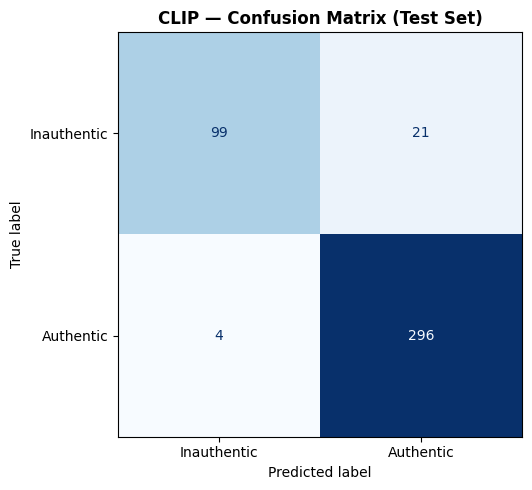

  True  Inauthentic (TN) : 99  — correctly flagged as fake
  False Authentic   (FP) : 21  — fake wrongly passed as authentic
  False Inauthentic (FN) : 4  — authentic wrongly flagged as fake
  True  Authentic   (TP) : 296  — correctly passed as authentic

  ⚠️  FP (21) = counterfeits CLIP missed
💾 Confusion matrix saved


In [ ]:
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Inauthentic', 'Authentic']
)
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('CLIP — Confusion Matrix (Test Set)', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/clip_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'  True  Inauthentic (TN) : {tn}  — correctly flagged as fake')
print(f'  False Authentic   (FP) : {fp}  — fake wrongly passed as authentic')
print(f'  False Inauthentic (FN) : {fn}  — authentic wrongly flagged as fake')
print(f'  True  Authentic   (TP) : {tp}  — correctly passed as authentic')
print(f'\n  ⚠️  FP ({fp}) = counterfeits CLIP missed')
print('💾 Confusion matrix saved')

---
## Cell 10 — Error Pattern Analysis

In [ ]:
df_results = df_test.copy()
df_results['pred_label'] = ['Authentic' if p == 1 else 'Inauthentic' for p in all_preds]
df_results['pred_prob']  = all_probs
df_results['correct']    = (all_preds == all_labels)
df_results['error_type'] = ''

df_results.loc[
    (df_results['Label'] == 'Inauthentic') &
    (df_results['pred_label'] == 'Authentic'), 'error_type'
] = 'False Positive'
df_results.loc[
    (df_results['Label'] == 'Authentic') &
    (df_results['pred_label'] == 'Inauthentic'), 'error_type'
] = 'False Negative'
df_results.loc[df_results['correct'], 'error_type'] = 'Correct'

print('📊 Error pattern analysis:')
print(df_results['error_type'].value_counts().to_string())

print('\n   Errors by category:')
print(df_results[df_results['error_type'] != 'Correct']
      .groupby(['ProductCategory', 'error_type']).size().unstack(fill_value=0).to_string())

errors = df_results[df_results['error_type'] != 'Correct']
print(f'\n   Mean confidence on errors : {errors["pred_prob"].mean():.4f}')

df_results.to_csv(f'{OUTPUT_DIR}/clip_test_results.csv', index=False)
print(f'\n💾 Full results saved to {OUTPUT_DIR}/clip_test_results.csv')

📊 Error pattern analysis:
error_type
Correct           395
False Positive     21
False Negative      4

   Errors by category:
error_type       False Negative  False Positive
ProductCategory                                
Bags                          1               6
Watches                       3              15

   Mean confidence on errors : 0.8529

💾 Full results saved to /content/drive/MyDrive/dataset/preprocessed/clip_test_results.csv


---
## Cell 11 — Per-Category Performance

In [ ]:
print('📊 Per-category performance:')
print(f'{"Category":12s}  {"Accuracy":10s}  {"F1":10s}  {"Recall(Inauth)":15s}  {"N"}')
print('─' * 60)

for cat in ['Bags', 'Watches', 'Shoes']:
    mask   = df_results['ProductCategory'] == cat
    y_true = df_results.loc[mask, 'label_int'].values
    y_pred = (df_results.loc[mask, 'pred_label'] == 'Authentic').astype(int).values

    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average='weighted')
    rec = recall_score(y_true, y_pred, pos_label=0, zero_division=0)
    n   = mask.sum()

    print(f'{cat:12s}  {acc:.4f}      {f1:.4f}      {rec:.4f}           {n}')

📊 Per-category performance:
Category      Accuracy    F1          Recall(Inauth)   N
────────────────────────────────────────────────────────────
Bags          0.9500      0.9489      0.8500           140
Watches       0.8714      0.8637      0.6250           140
Shoes         1.0000      1.0000      1.0000           140


---
## Cell 12 — Extract Survey Stimuli
CLIP stimuli are the most important ones for the survey —  
these are the outputs your consumer trust experiment is built around.

In [ ]:
stimuli_list = []

for cat in ['Bags', 'Watches', 'Shoes']:
    cat_df = df_results[df_results['ProductCategory'] == cat]

    correct_auth = cat_df[
        (cat_df['error_type'] == 'Correct') &
        (cat_df['Label'] == 'Authentic') &
        (cat_df['pred_prob'] > 0.75)
    ].head(2)

    correct_inauth = cat_df[
        (cat_df['error_type'] == 'Correct') &
        (cat_df['Label'] == 'Inauthentic') &
        (cat_df['pred_prob'] < 0.25)
    ].head(2)

    # False Positives — model missed fakes — used for 'AI Incorrect' condition
    incorrect = cat_df[
        (cat_df['error_type'] == 'False Positive') &
        (cat_df['pred_prob'].between(0.45, 0.70))
    ].head(2)

    stimuli_list.extend([correct_auth, correct_inauth, incorrect])

df_stimuli = pd.concat(stimuli_list, ignore_index=True)
survey_cols = [
    'ImageID', 'ProductID', 'ImagePath', 'ProductCategory',
    'ProductName', 'text_clean', 'Label', 'pred_label',
    'pred_prob', 'error_type'
]
df_stimuli = df_stimuli[survey_cols]
df_stimuli['model'] = 'CLIP'

df_stimuli.to_csv(f'{OUTPUT_DIR}/clip_survey_stimuli.csv', index=False)
print(f'✅ Survey stimuli extracted: {len(df_stimuli)} items')
print(df_stimuli.groupby(['ProductCategory', 'error_type']).size().to_string())
print(f'\n💾 Saved to {OUTPUT_DIR}/clip_survey_stimuli.csv')

✅ Survey stimuli extracted: 12 items
ProductCategory  error_type
Bags             Correct       4
Shoes            Correct       4
Watches          Correct       4

💾 Saved to /content/drive/MyDrive/dataset/preprocessed/clip_survey_stimuli.csv


---
## Cell 13 — Full Three-Model Comparison
The core result table for your paper.

In [ ]:
resnet_path  = f'{OUTPUT_DIR}/resnet50_test_results.csv'
roberta_path = f'{OUTPUT_DIR}/roberta_test_results.csv'

if os.path.exists(resnet_path) and os.path.exists(roberta_path):

    def load_results(path):
        df      = pd.read_csv(path)
        labels  = df['label_int'].values
        preds   = (df['pred_label'] == 'Authentic').astype(int).values
        probs   = df['pred_prob'].values
        return labels, preds, probs

    rn_labels,  rn_preds,  rn_probs  = load_results(resnet_path)
    rb_labels,  rb_preds,  rb_probs  = load_results(roberta_path)
    cl_labels,  cl_preds,  cl_probs  = all_labels, all_preds, all_probs

    def get_metrics(labels, preds, probs):
        return {
            'Accuracy':           accuracy_score(labels, preds),
            'AUC-ROC':            roc_auc_score(labels, probs),
            'F1 (weighted)':      f1_score(labels, preds, average='weighted'),
            'F1 (Inauthentic)':   f1_score(labels, preds, pos_label=0, average='binary'),
            'Recall (Inauth)':    recall_score(labels, preds, pos_label=0),
            'Precision (Inauth)': precision_score(labels, preds, pos_label=0, zero_division=0),
        }

    rn_m = get_metrics(rn_labels, rn_preds, rn_probs)
    rb_m = get_metrics(rb_labels, rb_preds, rb_probs)
    cl_m = get_metrics(cl_labels, cl_preds, cl_probs)

    print('━' * 72)
    print('  FULL MODEL COMPARISON — RQ1 RESULTS TABLE')
    print('━' * 72)
    print(f'{"Metric":22s}  {"ResNet-50":12s}  {"RoBERTa":12s}  {"CLIP":12s}  Best')
    print('─' * 72)

    for metric in rn_m:
        vals   = [rn_m[metric], rb_m[metric], cl_m[metric]]
        best_i = vals.index(max(vals))
        names  = ['ResNet-50', 'RoBERTa', 'CLIP']
        print(f'{metric:22s}  {vals[0]:.4f}        {vals[1]:.4f}        {vals[2]:.4f}        {names[best_i]}')

    print('━' * 72)

    # Check if CLIP outperforms both baselines on the critical metric
    clip_recall  = cl_m['Recall (Inauth)']
    rn_recall    = rn_m['Recall (Inauth)']
    rb_recall    = rb_m['Recall (Inauth)']

    print()
    if clip_recall > rn_recall and clip_recall > rb_recall:
        print('  ✅ CLIP achieves highest Recall (Inauthentic) — multimodal fusion')
        print('     outperforms both unimodal baselines. Supports H1 (RQ1).')
    else:
        print('  ⚠️  CLIP did not achieve highest Recall (Inauthentic).')
        print('     Review training — consider adjusting LR or epochs.')

    # Save comparison table as CSV
    rows = []
    for metric in rn_m:
        rows.append({
            'Metric':    metric,
            'ResNet-50': round(rn_m[metric], 4),
            'RoBERTa':   round(rb_m[metric], 4),
            'CLIP':      round(cl_m[metric], 4),
        })
    pd.DataFrame(rows).to_csv(f'{OUTPUT_DIR}/model_comparison.csv', index=False)
    print(f'\n💾 Comparison table saved to {OUTPUT_DIR}/model_comparison.csv')

else:
    print('⚠️  ResNet-50 or RoBERTa results not found.')
    print('   Run both baseline notebooks first for the full comparison.')

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  FULL MODEL COMPARISON — RQ1 RESULTS TABLE
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Metric                  ResNet-50     RoBERTa       CLIP          Best
────────────────────────────────────────────────────────────────────────
Accuracy                0.9143        0.9952        0.9405        RoBERTa
AUC-ROC                 0.9853        0.9994        0.9848        RoBERTa
F1 (weighted)           0.9095        0.9952        0.9390        RoBERTa
F1 (Inauthentic)        0.8252        0.9916        0.8879        RoBERTa
Recall (Inauth)         0.7083        0.9833        0.8250        RoBERTa
Precision (Inauth)      0.9884        1.0000        0.9612        RoBERTa
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  ⚠️  CLIP did not achieve highest Recall (Inauthentic).
     Review training — consider adjusting LR or epochs.

💾 Comparison table saved to /conte

---
## Cell 14 — Comparison Bar Chart
Publication-ready figure for your paper.

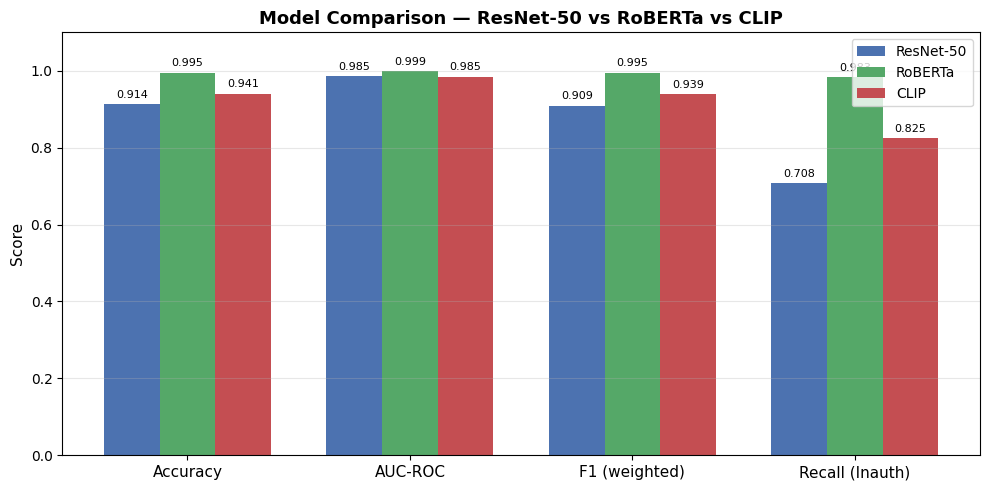

💾 Comparison chart saved


In [ ]:
comparison_path = f'{OUTPUT_DIR}/model_comparison.csv'

if os.path.exists(comparison_path):
    df_comp = pd.read_csv(comparison_path)

    # Select metrics to plot
    plot_metrics = ['Accuracy', 'AUC-ROC', 'F1 (weighted)', 'Recall (Inauth)']
    df_plot = df_comp[df_comp['Metric'].isin(plot_metrics)].set_index('Metric')
    df_plot = df_plot.loc[plot_metrics]   # preserve order

    x     = np.arange(len(plot_metrics))
    width = 0.25

    fig, ax = plt.subplots(figsize=(10, 5))
    bars1 = ax.bar(x - width, df_plot['ResNet-50'], width, label='ResNet-50', color='#4C72B0')
    bars2 = ax.bar(x,         df_plot['RoBERTa'],   width, label='RoBERTa',   color='#55A868')
    bars3 = ax.bar(x + width, df_plot['CLIP'],      width, label='CLIP',      color='#C44E52')

    ax.set_xticks(x)
    ax.set_xticklabels(plot_metrics, fontsize=11)
    ax.set_ylabel('Score', fontsize=11)
    ax.set_ylim(0, 1.1)
    ax.set_title('Model Comparison — ResNet-50 vs RoBERTa vs CLIP', fontsize=13, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)

    # Add value labels on bars
    for bars in [bars1, bars2, bars3]:
        for bar in bars:
            h = bar.get_height()
            ax.annotate(f'{h:.3f}',
                        xy=(bar.get_x() + bar.get_width() / 2, h),
                        xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=8)

    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/model_comparison_chart.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('💾 Comparison chart saved')
else:
    print('Run Cell 13 first to generate comparison data.')

---
## Cell 15 — Final Summary

In [ ]:
print('━' * 58)
print('  CLIP — FINAL SUMMARY (PRIMARY MULTIMODAL MODEL)')
print('━' * 58)
print(f'  Accuracy             : {accuracy_score(all_labels, all_preds):.4f}')
print(f'  AUC-ROC              : {roc_auc_score(all_labels, all_probs):.4f}')
print(f'  F1 (weighted)        : {f1_score(all_labels, all_preds, average="weighted"):.4f}')
print(f'  F1 (Inauthentic)     : {f1_score(all_labels, all_preds, pos_label=0, average="binary"):.4f}')
print(f'  Recall (Inauthentic) : {recall_score(all_labels, all_preds, pos_label=0):.4f}')
print(f'  Precision (Inauth)   : {precision_score(all_labels, all_preds, pos_label=0, zero_division=0):.4f}')
print('━' * 58)
print(f'  Best model saved     : {CFG["save_path"]}')
print(f'  Training curves      : {OUTPUT_DIR}/clip_curves.png')
print(f'  Confusion matrix     : {OUTPUT_DIR}/clip_confusion.png')
print(f'  Test results CSV     : {OUTPUT_DIR}/clip_test_results.csv')
print(f'  Survey stimuli CSV   : {OUTPUT_DIR}/clip_survey_stimuli.csv')
print(f'  Model comparison     : {OUTPUT_DIR}/model_comparison.csv')
print(f'  Comparison chart     : {OUTPUT_DIR}/model_comparison_chart.png')
print('━' * 58)
print()
print('📌 All three models complete.')
print('   Technical component of FYP is done.')
print()
print('🚀 Next steps:')
print('   1. Use clip_survey_stimuli.csv to build your survey stimuli')
print('   2. Design and launch your LimeSurvey / Qualtrics experiment')
print('   3. Collect responses (target n=200)')
print('   4. Analyse in SPSS — ANOVA, mediation (PROCESS Model 4),')
print('      moderation (PROCESS Model 1)')
print('   5. Write up and integrate AI results with survey findings')

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  CLIP — FINAL SUMMARY (PRIMARY MULTIMODAL MODEL)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Accuracy             : 0.9405
  AUC-ROC              : 0.9848
  F1 (weighted)        : 0.9390
  F1 (Inauthentic)     : 0.8879
  Recall (Inauthentic) : 0.8250
  Precision (Inauth)   : 0.9612
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Best model saved     : /content/drive/MyDrive/dataset/preprocessed/clip_best.pt
  Training curves      : /content/drive/MyDrive/dataset/preprocessed/clip_curves.png
  Confusion matrix     : /content/drive/MyDrive/dataset/preprocessed/clip_confusion.png
  Test results CSV     : /content/drive/MyDrive/dataset/preprocessed/clip_test_results.csv
  Survey stimuli CSV   : /content/drive/MyDrive/dataset/preprocessed/clip_survey_stimuli.csv
  Model comparison     : /content/drive/MyDrive/dataset/preprocessed/model_comparison.csv
  Comparison chart     : /content/drive/MyDrive/data